# EDA2 — Đánh giá giao dịch Fashion-MNIST

Notebook đối chiếu **15 codebook** và **45 bộ giao dịch** thuộc S0, S1, S3. Mỗi bộ đại diện cho cùng 70.000 ảnh. S0 dùng word toàn ảnh, S1 thêm vùng 2×2, S3 thêm dải ngang.

| Phần | Câu hỏi |
|---|---|
| **00. Chuẩn bị** | Đầu vào nào được dùng và đã kiểm định đến đâu? |
| **A. Codebook** | Độ méo, độ ổn định theo seed và centroid thay đổi thế nào theo K? |
| **B1–B5. Giao dịch** | Mã hóa ảnh hưởng thế nào đến độ dài, support, độ đa dạng và tương đồng theo lớp? |
| **C1–C3. Eclat** | Có bao nhiêu mẫu phổ biến và kết quả nhạy thế nào với ngưỡng support? |
| **D–E. Diễn giải và tổng hợp** | Mẫu nào đáng xem và đã đủ bằng chứng để chọn cấu hình chưa? |

Chạy từ trên xuống. Notebook mặc định đọc kết quả đã có trong **results/fashion/eda2/v2/**. Khi thiếu dữ liệu cơ sở, mục 00 và C1 sẽ tạo kết quả. C3 và D chỉ chạy mới khi bạn bật cờ tương ứng.

Mỗi mục có một hàm và biến kết quả riêng. Các mục A và B đọc bảng đã tính từ một lượt xử lý chung để mỗi bộ giao dịch chỉ cần được phân tích một lần. Các biểu đồ được hiển thị trong notebook và lưu dạng SVG trong thư mục **figures/notebook/** của lượt chạy.


## 00.1 Chuẩn bị môi trường và tùy chọn

Chọn K và seed để minh họa centroid, vùng ảnh và một số biểu đồ chi tiết. Các hình tổng quan vẫn dùng toàn bộ cấu hình đã chạy. Bật **TAO_LAI_AB** hoặc **TAO_LAI_C1** khi cần tính lại từ dữ liệu nguồn.

Chọn kernel **Julia Fashion-MNIST TC**. Nếu kernel chưa xuất hiện, đăng ký bằng lệnh **julia scripts/install_fashion_tc_kernel.jl** từ thư mục dự án.


In [1]:
using Pkg
using Markdown
using Statistics: mean, median
using TOML
using SHA: sha256

function tim_thu_muc_du_an(bat_dau=pwd())
    thu_muc = abspath(bat_dau)
    while !isfile(joinpath(thu_muc, "configs", "eda2_fashionmnist.toml"))
        thu_muc_cha = dirname(thu_muc)
        thu_muc_cha == thu_muc && error("Hãy mở notebook từ thư mục dự án EclatFIM.")
        thu_muc = thu_muc_cha
    end
    return thu_muc
end

thu_muc_du_an = tim_thu_muc_du_an()
Pkg.activate(thu_muc_du_an)
using EclatFIM
const EDA2 = EclatFIM.FashionMNISTEDA2

ctx = EDA2.load_context(
    joinpath(thu_muc_du_an, "configs", "eda2_fashionmnist.toml");
    repo_root=thu_muc_du_an,
)

TAO_LAI_AB = false
TAO_LAI_C1 = false
CHAY_C3 = false
TAO_MAU_DIEN_GIAI = false
GHI_LAI_BAO_CAO = false
K_MINH_HOA = 32
SEED_MINH_HOA = 42

(julia=string(VERSION), cau_hinh=ctx.config_path, thu_muc_ket_qua=ctx.output_root)


  Activating 

project at `/run/media/fernir/Data/Documents/HCMUS/SEMESTER7/DataMining/TeamProject-FrequentItemsetMining`


(julia = "1.13.3", cau_hinh = "/run/media/fernir/Data/Documents/HCMUS/SEMESTER7/DataMining/TeamProject-FrequentItemsetMining/configs/eda2_fashionmnist.toml", thu_muc_ket_qua = "/run/media/fernir/Data/Documents/HCMUS/SEMESTER7/DataMining/TeamProject-FrequentItemsetMining/results/fashion/eda2/v2")

## 00.2 Đọc bảng và vẽ biểu đồ

Các hàm dùng chung định dạng bảng Markdown và biểu đồ SVG. Khi một nhóm thiếu seed hoặc thiếu kết quả ở một ngưỡng support, biểu đồ để trống điểm tương ứng. Các bảng CSV lưu giá trị chi tiết theo từng cấu hình.


In [2]:
doc_bang(ctx, cac_phan...) = last(EDA2._read_csv(EDA2.output_path(ctx, cac_phan...)))
co_bang(ctx, cac_phan...) = isfile(EDA2.output_path(ctx, cac_phan...))

function so_thuc(chuoi)
    gia_tri = tryparse(Float64, chuoi)
    return isnothing(gia_tri) || !isfinite(gia_tri) ? missing : gia_tri
end

dinh_dang(x) = string(x)
dinh_dang(::Missing) = "—"
function dinh_dang(x::AbstractFloat)
    chuoi = string(round(x; digits=4))
    return endswith(chuoi, ".0") ? chop(chuoi; tail=2) : chuoi
end

function hien_bang(tieu_de, cot, dong)
    function o(x)
        chuoi = replace(dinh_dang(x), "|" => "\\|", '\n' => ' ')
        if occursin(r"^[A-Za-z0-9_]*_[A-Za-z0-9_]+$", chuoi)
            return string(Char(96), chuoi, Char(96))
        end
        return chuoi
    end
    tieu_de_bang = "### $tieu_de\n\n"
    tieu_de_bang *= "| " * join(o.(cot), " | ") * " |\n"
    tieu_de_bang *= "| " * join(fill("---", length(cot)), " | ") * " |\n"
    for hang in dong
        tieu_de_bang *= "| " * join(o.(collect(hang)), " | ") * " |\n"
    end
    display(MIME("text/markdown"), tieu_de_bang)
end

struct HinhEDA2
    noi_dung::String
end

Base.show(io::IO, ::MIME"image/svg+xml", hinh::HinhEDA2) = print(io, hinh.noi_dung)
Base.show(io::IO, ::MIME"text/plain", ::HinhEDA2) = print(io, "Biểu đồ SVG")

thoat_xml(x) = replace(string(x), '&' => "&amp;", '<' => "&lt;", '>' => "&gt;")
const MAU_BIEN_THE = Dict("S0" => "#2563eb", "S1" => "#be4a28", "S3" => "#087d66",
    "Seed 42" => "#2563eb", "Seed 123" => "#be4a28", "Seed 2026" => "#087d66")

function ve_xu_huong(ctx, tep, tieu_de, nhan_x, chuoi_du_lieu;
    truc_x="K", truc_y, mien_y=nothing, dang_cot=false)
    gia_tri = [y for (_, day) in chuoi_du_lieu for y in day if !ismissing(y)]
    isempty(gia_tri) && return nothing
    gioi_han = maximum(gia_tri)
    buoc = 10.0^floor(log10(max(gioi_han, eps()))) / 2
    tu, den = isnothing(mien_y) ? (0.0, gioi_han > 0 ? ceil(gioi_han / buoc) * buoc : 1.0) : mien_y
    rong, cao = 840, 388
    trai, phai, tren, duoi = 110, 805, 76, 308
    function x(i)
        dang_cot && return trai + (phai - trai) * (i - 0.5) / length(nhan_x)
        length(nhan_x) == 1 && return (trai + phai) / 2
        return trai + (phai - trai) * (i - 1) / (length(nhan_x) - 1)
    end
    y(v) = duoi - (duoi - tren) * (v - tu) / (den - tu)
    io = IOBuffer()
    println(io, """<svg xmlns="http://www.w3.org/2000/svg" role="img" width="$rong" height="$cao" viewBox="0 0 $rong $cao"><title>$(thoat_xml(tieu_de))</title>""")
    println(io, """<rect width="100%" height="100%" fill="#fff"/><g font-family="DejaVu Sans, sans-serif" fill="#1e293b">""")
    println(io, """<text x="$trai" y="26" font-size="17" font-weight="700">$(thoat_xml(tieu_de))</text>""")
    for v in range(tu, den; length=6)
        py = y(v)
        println(io, """<path d="M $trai $py H $phai" stroke="#e2e8f0"/><text x="$(trai - 9)" y="$(py + 4)" text-anchor="end" font-size="11">$(dinh_dang(v))</text>""")
    end
    println(io, """<path d="M $trai $tren V $duoi H $phai" fill="none" stroke="#64748b"/>""")
    for (i, nhan) in enumerate(nhan_x)
        println(io, """<text x="$(x(i))" y="$(duoi + 21)" text-anchor="middle" font-size="11">$(thoat_xml(nhan))</text>""")
    end
    println(io, """<text x="$((trai + phai) / 2)" y="$(cao - 14)" text-anchor="middle" font-size="13">$(thoat_xml(truc_x))</text>""")
    println(io, """<text transform="translate(24 $((tren + duoi) / 2)) rotate(-90)" text-anchor="middle" font-size="13">$(thoat_xml(truc_y))</text>""")
    for (j, (nhan, day)) in enumerate(chuoi_du_lieu)
        mau = get(MAU_BIEN_THE, nhan, "#2563eb")
        vi_tri_chu_giai = trai + 158 * (j - 1)
        gach = nhan == "S1" && !dang_cot ? "6 3" : "none"
        println(io, """<path d="M $vi_tri_chu_giai 47 h 18" stroke="$mau" stroke-width="3" stroke-dasharray="$gach"/><text x="$(vi_tri_chu_giai + 24)" y="51" font-size="12">$(thoat_xml(nhan))</text>""")
        for (i, v) in enumerate(day)
            ismissing(v) && continue
            ghi_chu = thoat_xml("$nhan • $(nhan_x[i]) • $(dinh_dang(v))")
            if dang_cot
                rong_cot = min(42, (phai - trai) / (2 * length(nhan_x)))
                println(io, """<rect x="$(x(i) - rong_cot / 2)" y="$(y(v))" width="$rong_cot" height="$(duoi - y(v))" fill="$mau"><title>$ghi_chu</title></rect>""")
            else
                if i > 1 && !ismissing(day[i-1])
                    println(io, """<path d="M $(x(i-1)) $(y(day[i-1])) L $(x(i)) $(y(v))" stroke="$mau" stroke-width="2" stroke-dasharray="$gach"/>""")
                end
                println(io, """<circle cx="$(x(i))" cy="$(y(v))" r="4" fill="$mau" stroke="#fff"><title>$ghi_chu</title></circle>""")
            end
        end
    end
    println(io, "</g></svg>")
    noi_dung = String(take!(io))
    duong_dan = EDA2.output_path(ctx, "figures", "notebook", "$tep.svg")
    mkpath(dirname(duong_dan))
    write(duong_dan, noi_dung)
    display(HinhEDA2(noi_dung))
    return duong_dan
end


function ve_heatmap_lop(ctx, within_rows, between_rows, k, seed, variant)
    ma = "B0_K$(k)_seed$(seed)_$(variant)"
    trong = Dict(parse(Int, r["class_id"]) + 1 => so_thuc(r["within_mean"])
        for r in within_rows if r["database_id"] == ma)
    giua = Dict((parse(Int, r["class_a"]) + 1, parse(Int, r["class_b"]) + 1) => so_thuc(r["between_mean"])
        for r in between_rows if r["database_id"] == ma)
    for a in 1:10
        giua[(a,a)] = get(trong, a, missing)
        for b in a+1:10
            giua[(b,a)] = get(giua, (a,b), missing)
        end
    end
    width, height, start, cell = 760, 610, 105, 42
    io = IOBuffer()
    println(io, """<svg xmlns="http://www.w3.org/2000/svg" width="$width" height="$height" viewBox="0 0 $width $height"><rect width="100%" height="100%" fill="white"/><text x="22" y="30" font-size="18" font-family="sans-serif">Jaccard trung bình theo cặp lớp · $variant · K=$k · seed=$seed</text>""")
    names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
    for a in 1:10
        println(io, """<text x="$(start-8)" y="$(start+(a-0.5)*cell+4)" text-anchor="end" font-size="11" font-family="sans-serif">$(names[a])</text><text x="$(start+(a-0.5)*cell)" y="$(start+10*cell+18)" text-anchor="middle" font-size="10" font-family="sans-serif">$(a-1)</text>""")
        for b in 1:10
            value = get(giua, (a,b), missing)
            color = ismissing(value) ? "#e5e7eb" : begin
                shade = round(Int, 245 - 190 * clamp(value, 0, 1))
                "rgb($shade,$shade,245)"
            end
            label = ismissing(value) ? "—" : string(round(value; digits=2))
            println(io, """<rect x="$(start+(b-1)*cell)" y="$(start+(a-1)*cell)" width="$cell" height="$cell" fill="$color" stroke="white"/><text x="$(start+(b-0.5)*cell)" y="$(start+(a-0.5)*cell+4)" text-anchor="middle" font-size="11" font-family="sans-serif">$label</text>""")
        end
    end
    println(io, """<text x="$(start+5*cell)" y="$(start+10*cell+48)" text-anchor="middle" font-size="12" font-family="sans-serif">Lớp cột</text><text transform="translate(18 $(start+5*cell)) rotate(-90)" text-anchor="middle" font-size="12" font-family="sans-serif">Lớp hàng</text></svg>""")
    svg = String(take!(io))
    path = EDA2.output_path(ctx, "figures", "notebook", "b5_heatmap_$(variant)_K$(k)_seed$(seed).svg")
    mkpath(dirname(path)); write(path, svg); display(HinhEDA2(svg))
    return path
end


function ve_boxplot_dai(ctx, rows, k, seed)
    data=[only(filter(r->r["K"]==string(k)&&r["seed"]==string(seed)&&r["variant"]==v,rows)) for v in EDA2.VARIANTS]
    width,height,left,right,top,bottom=760,400,110,720,60,320
    max_value=maximum(parse(Float64,r["max_length"]) for r in data)
    y(v)=bottom-(bottom-top)*v/max(max_value,1.0)
    io=IOBuffer()
    println(io,"""<svg xmlns="http://www.w3.org/2000/svg" width="$width" height="$height" viewBox="0 0 $width $height"><rect width="100%" height="100%" fill="white"/><text x="22" y="30" font-size="18" font-family="sans-serif">Boxplot độ dài từ P5–P95 · K=$k · seed=$seed</text>""")
    for (i,(variant,row)) in enumerate(zip(EDA2.VARIANTS,data))
        x=left+(right-left)*(i-0.5)/length(data)
        lo=parse(Float64,row["p5_length"]); q1=parse(Float64,row["p25_length"])
        med=parse(Float64,row["median_length"]); q3=parse(Float64,row["p75_length"])
        hi=parse(Float64,row["p95_length"]); color=MAU_BIEN_THE[variant]
        println(io,"""<path d="M $x $(y(hi)) V $(y(lo)) M $(x-10) $(y(hi)) H $(x+10) M $(x-10) $(y(lo)) H $(x+10)" stroke="$color" stroke-width="2"/><rect x="$(x-28)" y="$(y(q3))" width="56" height="$(max(1,y(q1)-y(q3)))" fill="$color" fill-opacity="0.28" stroke="$color"/><path d="M $(x-28) $(y(med)) H $(x+28)" stroke="$color" stroke-width="3"/><text x="$x" y="$(bottom+25)" text-anchor="middle" font-size="13" font-family="sans-serif">$variant · P50 $(round(med;digits=1))</text>""")
    end
    for tick in range(0,max_value;length=6)
        println(io,"""<path d="M $left $(y(tick)) H $right" stroke="#e2e8f0"/><text x="$(left-8)" y="$(y(tick)+4)" text-anchor="end" font-size="11" font-family="sans-serif">$(round(tick;digits=1))</text>""")
    end
    println(io,"""<path d="M $left $top V $bottom H $right" fill="none" stroke="#64748b"/><text transform="translate(25 $((top+bottom)/2)) rotate(-90)" text-anchor="middle" font-size="12" font-family="sans-serif">Số item / ảnh</text></svg>""")
    svg=String(take!(io)); path=EDA2.output_path(ctx,"figures","notebook","b1_boxplot.svg")
    mkpath(dirname(path));write(path,svg);display(HinhEDA2(svg));return path
end

function tong_hop_theo_k(dong, cot; thong_ke=mean, he_so=1.0)
    return [bien_the => [
        begin
            nhom = [r for r in dong if r["K"] == string(k) && r["variant"] == bien_the]
            seeds = Set(r["seed"] for r in nhom)
            du_seed = length(nhom) == length(EDA2.EXPECTED_SEEDS) &&
                seeds == Set(string.(EDA2.EXPECTED_SEEDS))
            day = [so_thuc(r[cot]) for r in nhom]
            du_seed && all(!ismissing, day) ? he_so * thong_ke(skipmissing(day)) : missing
        end for k in EDA2.EXPECTED_K
    ] for bien_the in EDA2.VARIANTS]
end

function ve_theo_k(ctx, dong, cot, tep, tieu_de; truc_y, thong_ke=mean, he_so=1.0, mien_y=nothing)
    chuoi = tong_hop_theo_k(dong, cot; thong_ke, he_so)
    return ve_xu_huong(ctx, tep, tieu_de, string.(EDA2.EXPECTED_K), chuoi; truc_y, mien_y)
end

function hien_bang_theo_k(tieu_de, dong, cot; thong_ke=mean, he_so=1.0)
    chuoi = tong_hop_theo_k(dong, cot; thong_ke, he_so)
    hang = [(k, (last(day)[i] for day in chuoi)...) for (i, k) in enumerate(EDA2.EXPECTED_K)]
    hien_bang(tieu_de, ["K"; EDA2.VARIANTS], hang)
    return hang
end


hien_bang_theo_k (generic function with 1 method)

## 00.3 Kiểm định đầu vào và chuẩn bị A/B

Đối chiếu mã bộ dữ liệu, trạng thái đọc lại, ánh xạ TID tới ảnh và dòng dõi về S0. Bảng bên dưới báo số bộ **PASS** và **BLOCKED** theo từng biến thể. Khi chạy A/B mới, nhật ký hiển thị tiến độ theo cặp K và seed.


In [3]:
function chuan_bi_ab(ctx; tinh_lai=false)
    specs = EDA2.discover_inputs(ctx)
    bao_cao = EDA2.output_path(ctx, "validation_report.toml")
    cac_tep = [
        ("input_manifest.csv",),
        ("codebook", "codebook_metrics_15.csv"),
        ("codebook", "codebook_metrics_by_k.csv"),
        ("codebook", "codebook_flags.csv"),
        ("transactions", "transaction_metrics_45.csv"),
        ("transactions", "paired_encoding_comparison.csv"),
        ("transactions", "transaction_length_histogram_45.csv"),
        ("transactions", "item_support_summary_45.csv"),
        ("transactions", "transaction_diversity_45.csv"),
        ("transactions", "spatial_invariants_45.csv"),
        ("transactions", "region_support_summary.csv"),
        ("transactions", "class_similarity_summary_45.csv"),
    ]
    if tinh_lai || !isfile(bao_cao) || !all(tep -> co_bang(ctx, tep...), cac_tep)
        EDA2.run_analysis_a!(ctx)
    end
    bao_cao_doc = TOML.parsefile(bao_cao)
    danh_muc = doc_bang(ctx, "input_manifest.csv")
    Set(r["database_id"] for r in danh_muc) == Set(s.database_id for s in specs) ||
        error("Danh mục khác phạm vi EDA2 hiện tại. Bật TAO_LAI_AB để tạo lại.")
    tom_tat = [(bien_the,
        count(r -> r["variant"] == bien_the && r["status"] == "PASS", danh_muc),
        count(r -> r["variant"] == bien_the && r["status"] == "BLOCKED", danh_muc))
        for bien_the in EDA2.VARIANTS]
    hien_bang("Kết quả kiểm định", ["Biến thể", "PASS", "BLOCKED"], tom_tat)
    return (bao_cao=bao_cao_doc, danh_muc=danh_muc, tom_tat=tom_tat)
end

ket_qua_00 = chuan_bi_ab(ctx; tinh_lai=TAO_LAI_AB)
println("Trạng thái: ", ket_qua_00.bao_cao["status"])


### Kết quả kiểm định

| Biến thể | PASS | BLOCKED |
| --- | --- | --- |
| S0 | 15 | 0 |
| S1 | 15 | 0 |
| S3 | 15 | 0 |


Trạng thái: PASS


## A. Chất lượng codebook

Mỗi điểm là trung bình qua ba seed. Độ méo thấp biểu thị centroid gần descriptor hơn. ARI là chỉ số ổn định được lưu từ TC4, cần xác minh nguồn mẫu descriptor trước khi diễn giải. Gallery phía dưới dùng một codebook minh họa.


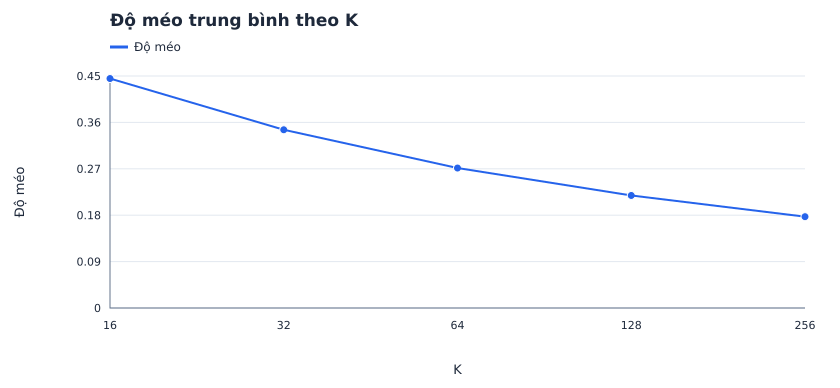

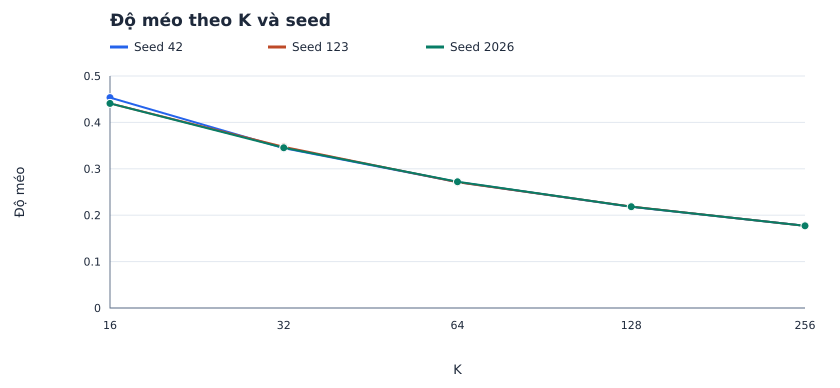

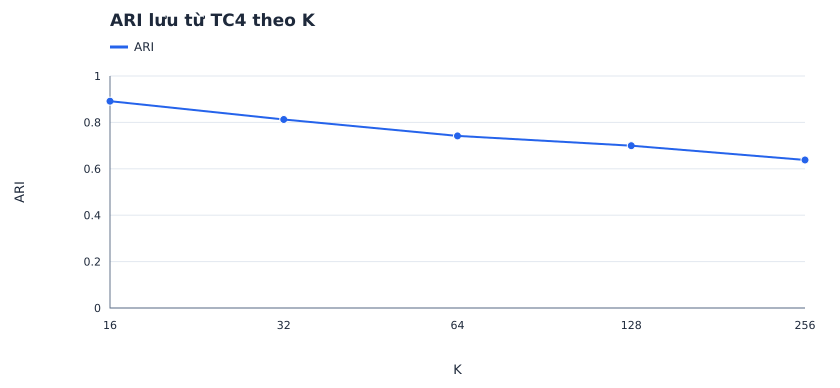

### Chỉ số trung bình qua ba seed

| K | Số seed | Độ méo | Tỷ lệ cụm có mẫu | ARI lưu từ TC4 |
| --- | --- | --- | --- | --- |
| 16 | 3 | 0.4451 | 1 | 0.8914 |
| 32 | 3 | 0.3457 | 1 | 0.8125 |
| 64 | 3 | 0.2715 | 1 | 0.7417 |
| 128 | 3 | 0.2183 | 1 | 0.6996 |
| 256 | 3 | 0.1771 | 1 | 0.638 |


### Cảnh báo hội tụ

| K | Seed | Trạng thái | Lý do dừng |
| --- | --- | --- | --- |
| 128 | 42 | `NON_CONVERGED` | `max_iterations` |
| 256 | 123 | `NON_CONVERGED` | `max_iterations` |


**Centroid 4×4 cho K=32, seed=42**

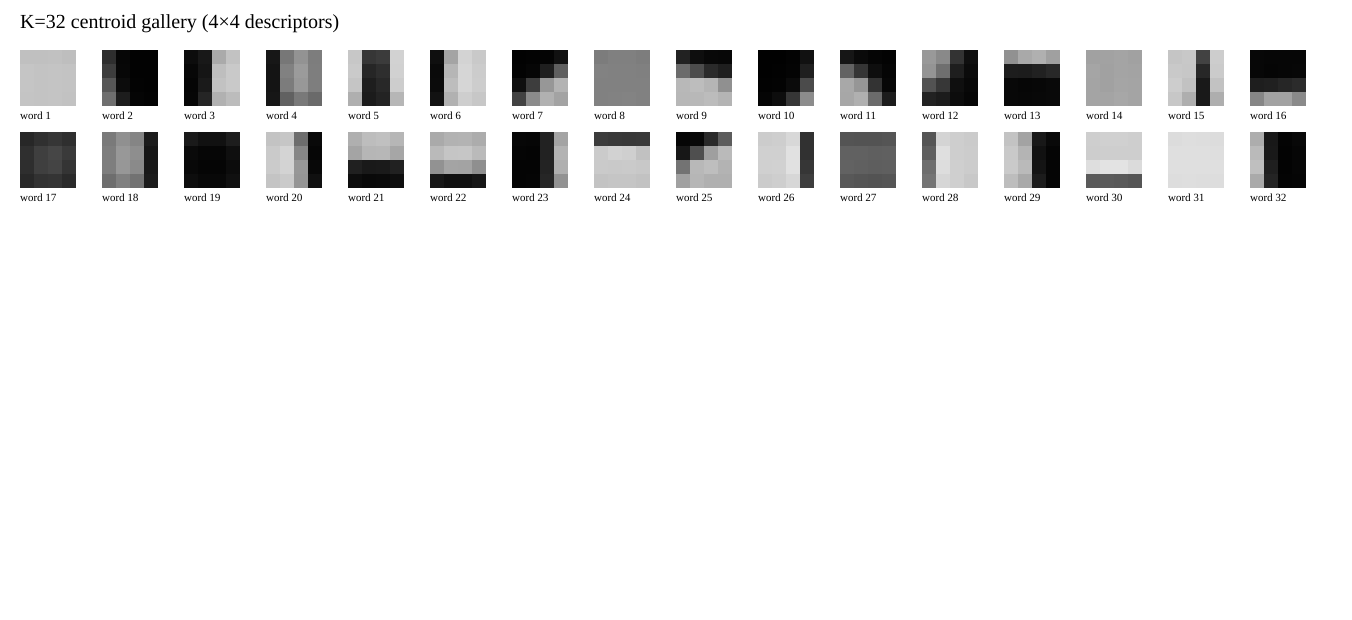

In [4]:
function phan_tich_codebook(ctx; k_minh_hoa, seed_minh_hoa)
    tong_hop = doc_bang(ctx, "codebook", "codebook_metrics_by_k.csv")
    theo_seed = doc_bang(ctx, "codebook", "codebook_metrics_15.csv")
    canh_bao = [r for r in doc_bang(ctx, "codebook", "codebook_flags.csv") if r["flag"] != "CONVERGED"]
    cac_k = [r["K"] for r in tong_hop]
    ve(cot, ten, tieu_de, don_vi; mien_y=nothing) =
        ve_xu_huong(ctx, ten, tieu_de, cac_k, [don_vi => [so_thuc(r[cot]) for r in tong_hop]];
            truc_y=don_vi, mien_y)
    hinh_do_meo = ve("distortion_mean", "a_do_meo", "Độ méo trung bình theo K", "Độ méo")
    chuoi_seed = ["Seed $seed" => [
        so_thuc(first(filter(r -> r["K"] == string(k) && r["seed"] == string(seed), theo_seed))["distortion"])
        for k in EDA2.EXPECTED_K] for seed in EDA2.EXPECTED_SEEDS]
    hinh_do_meo_seed = ve_xu_huong(ctx, "a_do_meo_theo_seed", "Độ méo theo K và seed",
        string.(EDA2.EXPECTED_K), chuoi_seed; truc_y="Độ méo")
    hinh_ari = ve("saved_ari_mean", "a_ari", "ARI lưu từ TC4 theo K", "ARI"; mien_y=(0, 1))
    bang = [(r["K"], r["seed_count"], so_thuc(r["distortion_mean"]), so_thuc(r["occupancy_mean"]),
        so_thuc(r["saved_ari_mean"])) for r in tong_hop]
    hien_bang("Chỉ số trung bình qua ba seed", ["K", "Số seed", "Độ méo", "Tỷ lệ cụm có mẫu", "ARI lưu từ TC4"], bang)
    if !isempty(canh_bao)
        hien_bang("Cảnh báo hội tụ", ["K", "Seed", "Trạng thái", "Lý do dừng"],
            [(r["K"], r["seed"], r["flag"], r["stop_reason"]) for r in canh_bao])
    end
    gallery = EDA2.output_path(ctx, "codebook", "figures", "centroids_K$(k_minh_hoa)_seed$(seed_minh_hoa).svg")
    if isfile(gallery)
        display(MIME("text/markdown"), "**Centroid 4×4 cho K=$k_minh_hoa, seed=$seed_minh_hoa**")
        display(HinhEDA2(read(gallery, String)))
    end
    return (tong_hop=tong_hop, theo_seed=theo_seed, canh_bao=canh_bao,
        hinh=[hinh_do_meo, hinh_do_meo_seed, hinh_ari], gallery=isfile(gallery) ? gallery : nothing)
end

ket_qua_a = phan_tich_codebook(ctx; k_minh_hoa=K_MINH_HOA, seed_minh_hoa=SEED_MINH_HOA);


## B1. Độ dài, mật độ và giao dịch rỗng

Độ dài là số item khác nhau trong một ảnh. Mật độ dùng kích thước toàn bộ tập item có thể mã hóa của từng biến thể. Vì mẫu số thay đổi giữa S0, S1 và S3, hãy đọc mật độ cùng với độ dài.


### Số item trung bình trên mỗi ảnh

| K | S0 | S1 | S3 |
| --- | --- | --- | --- |
| 16 | 8.8592 | 15.455 | 13.4252 |
| 32 | 12.2778 | 18.2222 | 16.5165 |
| 64 | 15.1298 | 20.3148 | 18.7917 |
| 128 | 17.9644 | 22.3586 | 21.0693 |
| 256 | 20.3718 | 24.0437 | 22.9696 |


### Thống kê độ dài · K × biến thể × seed

| K | Seed | Biến thể | Min | P5 | P25 | Trung vị | P75 | P95 | P99 | Max | Rỗng | Độ dài 1 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 16 | 42 | S0 | 2 | 5.0 | 7.0 | 9.0 | 10.0 | 12.0 | 13.0 | 16 | 0 | 0 |
| 16 | 42 | S1 | 3 | 9.0 | 12.0 | 15.0 | 18.0 | 21.0 | 24.0 | 35 | 0 | 0 |
| 16 | 42 | S3 | 2 | 7.0 | 11.0 | 13.0 | 16.0 | 19.0 | 21.0 | 30 | 0 | 0 |
| 16 | 123 | S0 | 2 | 5.0 | 8.0 | 9.0 | 11.0 | 13.0 | 14.0 | 16 | 0 | 0 |
| 16 | 123 | S1 | 3 | 9.0 | 13.0 | 16.0 | 18.0 | 22.0 | 24.0 | 35 | 0 | 0 |
| 16 | 123 | S3 | 2 | 7.0 | 11.0 | 14.0 | 16.0 | 19.0 | 22.0 | 30 | 0 | 0 |
| 16 | 2026 | S0 | 2 | 5.0 | 8.0 | 9.0 | 11.0 | 13.0 | 14.0 | 16 | 0 | 0 |
| 16 | 2026 | S1 | 3 | 9.0 | 13.0 | 16.0 | 18.0 | 22.0 | 24.0 | 35 | 0 | 0 |
| 16 | 2026 | S3 | 2 | 7.0 | 11.0 | 14.0 | 16.0 | 19.0 | 22.0 | 30 | 0 | 0 |
| 32 | 42 | S0 | 1 | 7.0 | 10.0 | 12.0 | 14.0 | 17.0 | 19.0 | 25 | 0 | 1 |
| 32 | 42 | S1 | 3 | 11.0 | 15.0 | 18.0 | 21.0 | 25.0 | 29.0 | 40 | 0 | 0 |
| 32 | 42 | S3 | 2 | 10.0 | 14.0 | 17.0 | 19.0 | 23.0 | 26.0 | 38 | 0 | 0 |
| 32 | 123 | S0 | 2 | 7.0 | 10.0 | 12.0 | 14.0 | 17.0 | 19.0 | 26 | 0 | 0 |
| 32 | 123 | S1 | 3 | 11.0 | 15.0 | 18.0 | 21.0 | 25.0 | 28.0 | 39 | 0 | 0 |
| 32 | 123 | S3 | 2 | 10.0 | 14.0 | 16.0 | 19.0 | 23.0 | 26.0 | 35 | 0 | 0 |
| 32 | 2026 | S0 | 2 | 7.0 | 10.0 | 12.0 | 14.0 | 17.0 | 19.0 | 25 | 0 | 0 |
| 32 | 2026 | S1 | 3 | 11.0 | 15.0 | 18.0 | 21.0 | 25.0 | 28.0 | 39 | 0 | 0 |
| 32 | 2026 | S3 | 2 | 9.950000000000273 | 14.0 | 17.0 | 19.0 | 23.0 | 26.0 | 36 | 0 | 0 |
| 64 | 42 | S0 | 2 | 9.0 | 13.0 | 15.0 | 18.0 | 21.0 | 24.0 | 35 | 0 | 0 |
| 64 | 42 | S1 | 3 | 12.0 | 17.0 | 21.0 | 24.0 | 28.0 | 32.0 | 44 | 0 | 0 |
| 64 | 42 | S3 | 2 | 11.0 | 16.0 | 19.0 | 22.0 | 27.0 | 30.0 | 40 | 0 | 0 |
| 64 | 123 | S0 | 2 | 9.0 | 13.0 | 15.0 | 18.0 | 21.0 | 24.0 | 35 | 0 | 0 |
| 64 | 123 | S1 | 3 | 12.0 | 17.0 | 20.0 | 24.0 | 28.0 | 32.0 | 43 | 0 | 0 |
| 64 | 123 | S3 | 2 | 11.0 | 16.0 | 19.0 | 22.0 | 26.0 | 30.0 | 41 | 0 | 0 |
| 64 | 2026 | S0 | 2 | 9.0 | 13.0 | 15.0 | 18.0 | 21.0 | 24.0 | 34 | 0 | 0 |
| 64 | 2026 | S1 | 3 | 12.0 | 17.0 | 20.0 | 24.0 | 28.0 | 32.0 | 43 | 0 | 0 |
| 64 | 2026 | S3 | 2 | 11.0 | 16.0 | 19.0 | 22.0 | 26.0 | 30.0 | 40 | 0 | 0 |
| 128 | 42 | S0 | 3 | 11.0 | 15.0 | 18.0 | 21.0 | 25.0 | 29.0 | 39 | 0 | 0 |
| 128 | 42 | S1 | 4 | 14.0 | 18.0 | 22.0 | 26.0 | 31.0 | 35.0 | 46 | 0 | 0 |
| 128 | 42 | S3 | 3 | 13.0 | 18.0 | 21.0 | 25.0 | 30.0 | 33.0 | 44 | 0 | 0 |
| 128 | 123 | S0 | 2 | 11.0 | 15.0 | 18.0 | 21.0 | 25.0 | 29.0 | 39 | 0 | 0 |
| 128 | 123 | S1 | 4 | 14.0 | 18.0 | 23.0 | 26.0 | 31.0 | 35.0 | 45 | 0 | 0 |
| 128 | 123 | S3 | 2 | 13.0 | 18.0 | 21.0 | 25.0 | 30.0 | 33.0 | 42 | 0 | 0 |
| 128 | 2026 | S0 | 3 | 11.0 | 15.0 | 18.0 | 21.0 | 25.0 | 29.0 | 38 | 0 | 0 |
| 128 | 2026 | S1 | 4 | 14.0 | 18.0 | 22.0 | 26.0 | 31.0 | 35.0 | 45 | 0 | 0 |
| 128 | 2026 | S3 | 3 | 13.0 | 17.0 | 21.0 | 25.0 | 30.0 | 33.0 | 43 | 0 | 0 |
| 256 | 42 | S0 | 3 | 13.0 | 17.0 | 20.0 | 24.0 | 29.0 | 32.0 | 43 | 0 | 0 |
| 256 | 42 | S1 | 4 | 15.0 | 20.0 | 24.0 | 28.0 | 34.0 | 37.0 | 47 | 0 | 0 |
| 256 | 42 | S3 | 3 | 14.0 | 19.0 | 23.0 | 27.0 | 32.0 | 36.0 | 46 | 0 | 0 |
| 256 | 123 | S0 | 3 | 13.0 | 17.0 | 20.0 | 24.0 | 28.0 | 32.0 | 41 | 0 | 0 |
| 256 | 123 | S1 | 4 | 15.0 | 20.0 | 24.0 | 28.0 | 33.0 | 37.0 | 46 | 0 | 0 |
| 256 | 123 | S3 | 3 | 14.0 | 19.0 | 23.0 | 27.0 | 32.0 | 36.0 | 47 | 0 | 0 |
| 256 | 2026 | S0 | 3 | 13.0 | 17.0 | 20.0 | 24.0 | 29.0 | 32.0 | 42 | 0 | 0 |
| 256 | 2026 | S1 | 4 | 15.0 | 20.0 | 24.0 | 28.0 | 33.0 | 37.0 | 47 | 0 | 0 |
| 256 | 2026 | S3 | 3 | 14.0 | 19.0 | 23.0 | 27.0 | 32.0 | 36.0 | 46 | 0 | 0 |


### So sánh ghép cặp từng TID với S0

| K | Seed | Biến thể | Chênh lệch độ dài TB | P5 | P95 | Lệch trạng thái rỗng |
| --- | --- | --- | --- | --- | --- | --- |
| 16 | 42 | S1 | 6.6853 | 3 | 11 | 0 |
| 16 | 42 | S3 | 4.6322 | 0 | 8 | 0 |
| 16 | 123 | S1 | 6.5518 | 3 | 11 | 0 |
| 16 | 123 | S3 | 4.533 | 0 | 8 | 0 |
| 16 | 2026 | S1 | 6.5502 | 3 | 11 | 0 |
| 16 | 2026 | S3 | 4.5328 | 0 | 8 | 0 |
| 32 | 42 | S1 | 5.9445 | 2 | 10 | 0 |
| 32 | 42 | S3 | 4.2614 | 0 | 8 | 0 |
| 32 | 123 | S1 | 5.9316 | 2 | 10 | 0 |
| 32 | 123 | S3 | 4.2081 | 0 | 8 | 0 |
| 32 | 2026 | S1 | 5.9568 | 2 | 10 | 0 |
| 32 | 2026 | S3 | 4.2465 | 0 | 8 | 0 |
| 64 | 42 | S1 | 5.2387 | 1 | 10 | 0 |
| 64 | 42 | S3 | 3.7131 | 0 | 7 | 0 |
| 64 | 123 | S1 | 5.1626 | 1 | 10 | 0 |
| 64 | 123 | S3 | 3.648 | 0 | 7 | 0 |
| 64 | 2026 | S1 | 5.1538 | 1 | 9 | 0 |
| 64 | 2026 | S3 | 3.6246 | 0 | 7 | 0 |
| 128 | 42 | S1 | 4.3265 | 1 | 9 | 0 |
| 128 | 42 | S3 | 3.0552 | 0 | 7 | 0 |
| 128 | 123 | S1 | 4.4083 | 1 | 9 | 0 |
| 128 | 123 | S3 | 3.1087 | 0 | 7 | 0 |
| 128 | 2026 | S1 | 4.4478 | 1 | 9 | 0 |
| 128 | 2026 | S3 | 3.1508 | 0 | 7 | 0 |
| 256 | 42 | S1 | 3.6454 | 0 | 8 | 0 |
| 256 | 42 | S3 | 2.5976 | 0 | 6 | 0 |
| 256 | 123 | S1 | 3.7132 | 0 | 8 | 0 |
| 256 | 123 | S3 | 2.6303 | 0 | 6 | 0 |
| 256 | 2026 | S1 | 3.657 | 0 | 8 | 0 |
| 256 | 2026 | S3 | 2.5653 | 0 | 6 | 0 |


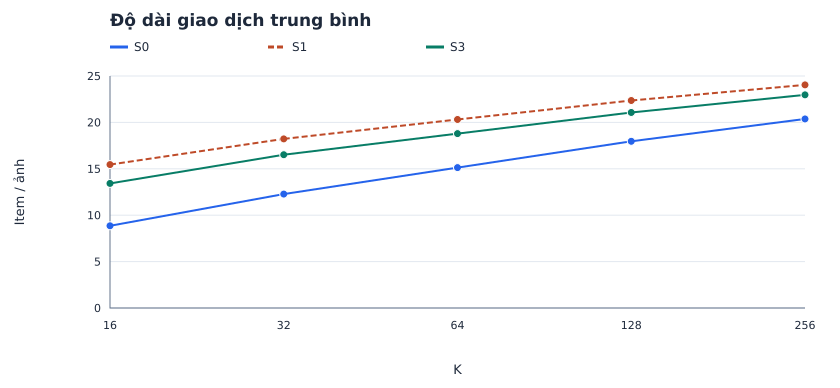

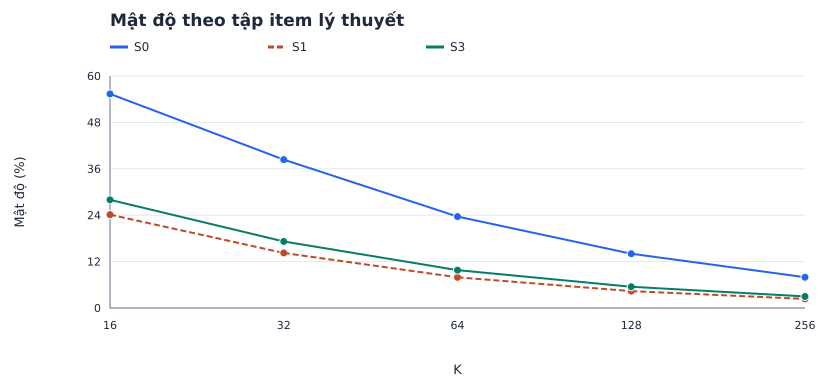

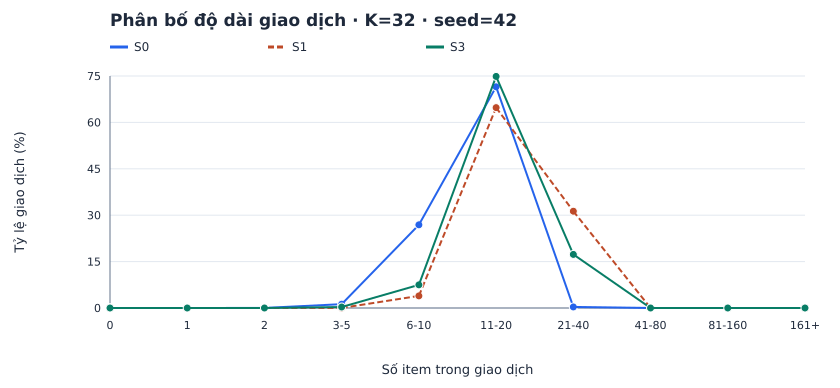

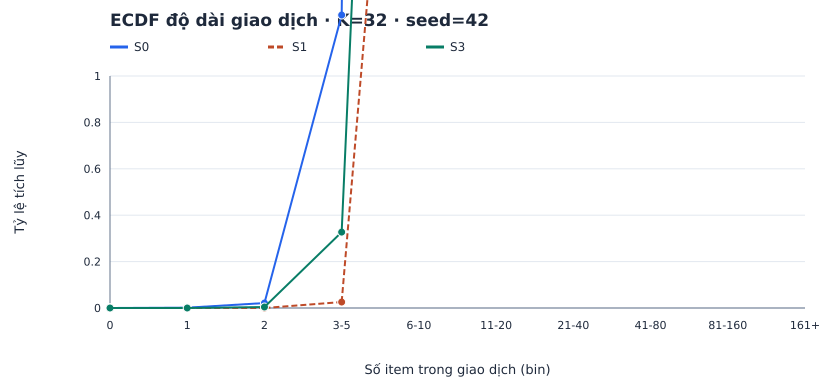

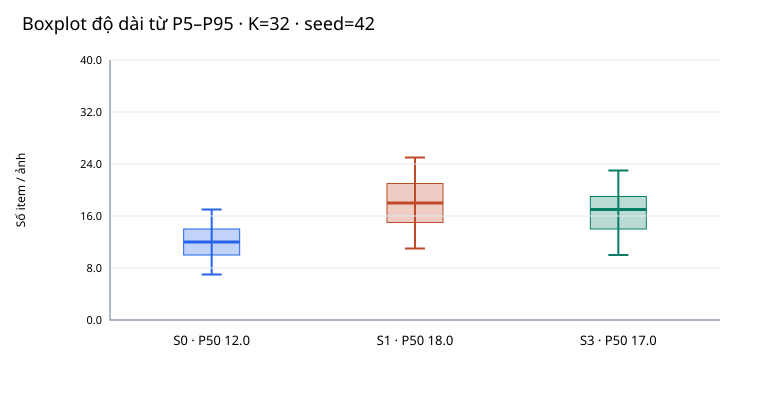

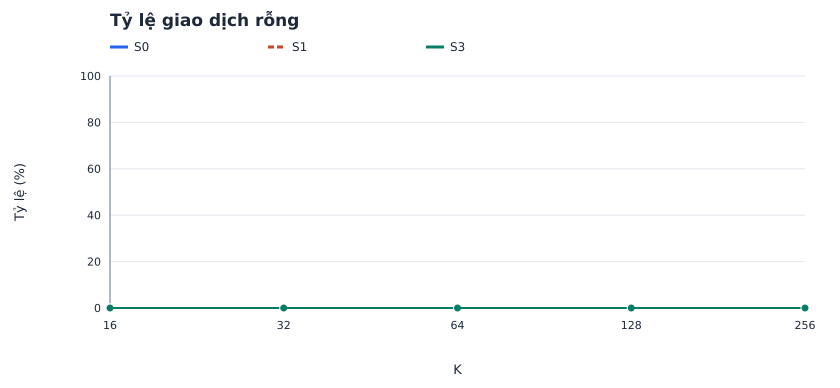

Số bộ có giao dịch rỗng: 0/45


In [5]:
function phan_tich_do_dai(ctx)
    dong = doc_bang(ctx, "transactions", "transaction_metrics_45.csv")
    danh_muc_do_dai = doc_bang(ctx, "transactions", "transaction_length_histogram_45.csv")
    bang = hien_bang_theo_k("Số item trung bình trên mỗi ảnh", dong, "mean_length")
    hien_bang("Thống kê độ dài · K × biến thể × seed",
        ["K","Seed","Biến thể","Min","P5","P25","Trung vị","P75","P95","P99","Max","Rỗng","Độ dài 1"],
        [(r["K"],r["seed"],r["variant"],r["min_length"],r["p5_length"],r["p25_length"],
          r["median_length"],r["p75_length"],r["p95_length"],r["p99_length"],r["max_length"],
          r["empty_count"],r["length1_count"]) for r in dong])
    paired = doc_bang(ctx, "transactions", "paired_encoding_comparison.csv")
    hien_bang("So sánh ghép cặp từng TID với S0",
        ["K", "Seed", "Biến thể", "Chênh lệch độ dài TB", "P5", "P95", "Lệch trạng thái rỗng"],
        [(r["K"], r["seed"], r["variant"], so_thuc(r["length_delta_mean_vs_s0"]),
          so_thuc(r["length_delta_p5_vs_s0"]), so_thuc(r["length_delta_p95_vs_s0"]),
          r["empty_status_mismatches"]) for r in paired])
    hinh_do_dai = ve_theo_k(ctx, dong, "mean_length", "b1_do_dai", "Độ dài giao dịch trung bình"; truc_y="Item / ảnh")
    hinh_mat_do = ve_theo_k(ctx, dong, "density_theoretical", "b1_mat_do", "Mật độ theo tập item lý thuyết"; truc_y="Mật độ (%)", he_so=100)
    histogram_minh_hoa = [r for r in danh_muc_do_dai if r["K"] == string(K_MINH_HOA) &&
        r["seed"] == string(SEED_MINH_HOA)]
    bins = sort!(unique(r["length_bin"] for r in histogram_minh_hoa);
        by=x -> findfirst(==(x), ["0","1","2","3-5","6-10","11-20","21-40","41-80","81-160","161+"]))
    histogram_series = [variant => [
        begin
            row = findfirst(r -> r["variant"] == variant && r["length_bin"] == bin, histogram_minh_hoa)
            isnothing(row) ? missing : 100 * parse(Float64, histogram_minh_hoa[row]["fraction"])
        end for bin in bins
    ] for variant in EDA2.VARIANTS]
    hinh_phan_bo = ve_xu_huong(ctx, "b1_histogram", "Phân bố độ dài giao dịch · K=$K_MINH_HOA · seed=$SEED_MINH_HOA",
        bins, histogram_series; truc_x="Số item trong giao dịch", truc_y="Tỷ lệ giao dịch (%)")
    ecdf_series = [variant => cumsum(last(histogram_series[j])) for (j,variant) in enumerate(EDA2.VARIANTS)]
    hinh_ecdf = ve_xu_huong(ctx, "b1_ecdf", "ECDF độ dài giao dịch · K=$K_MINH_HOA · seed=$SEED_MINH_HOA",
        bins, ecdf_series; truc_x="Số item trong giao dịch (bin)", truc_y="Tỷ lệ tích lũy", mien_y=(0,1))
    hinh_boxplot = ve_boxplot_dai(ctx,dong,K_MINH_HOA,SEED_MINH_HOA)
    hinh_rong = ve_theo_k(ctx, dong, "empty_rate", "b1_giao_dich_rong",
        "Tỷ lệ giao dịch rỗng"; truc_y="Tỷ lệ (%)", he_so=100, mien_y=(0, 100))
    bo_co_giao_dich_rong = count(r -> parse(Int, r["empty_count"]) > 0, dong)
    println("Số bộ có giao dịch rỗng: $bo_co_giao_dich_rong/$(length(dong))")
    return (chi_tiet=dong, phan_bo_do_dai=danh_muc_do_dai, bang=bang,
        bo_co_giao_dich_rong=bo_co_giao_dich_rong, hinh=[hinh_do_dai, hinh_mat_do, hinh_phan_bo, hinh_ecdf, hinh_boxplot, hinh_rong])
end

ket_qua_b1 = phan_tich_do_dai(ctx);


## B2. Support của từng item

Support của một item là tỷ lệ ảnh chứa item đó, lấy trên đủ 70.000 ảnh. Biểu đồ minh họa số **item đơn** vượt các ngưỡng support, lấy trung bình qua ba seed tại K đã chọn.


### Số item đơn phổ biến tại K=32

| Support | S0 | S1 | S3 |
| --- | --- | --- | --- |
| 1% | 32 | 120 | 93.3333 |
| 3% | 32 | 104 | 84.3333 |
| 5% | 32 | 87.6667 | 82 |
| 10% | 31.6667 | 74.3333 | 72.3333 |


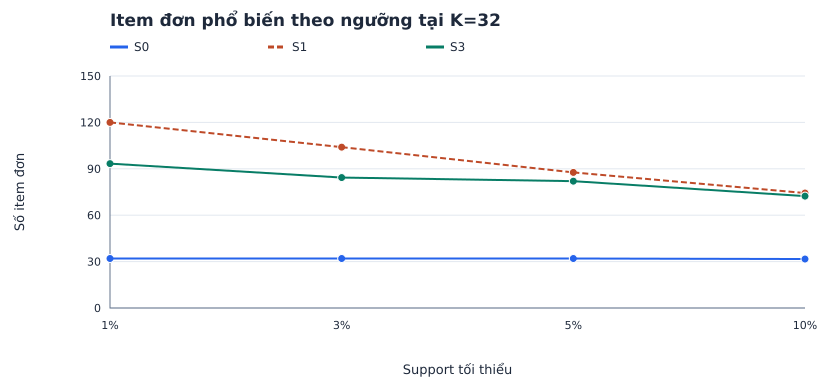

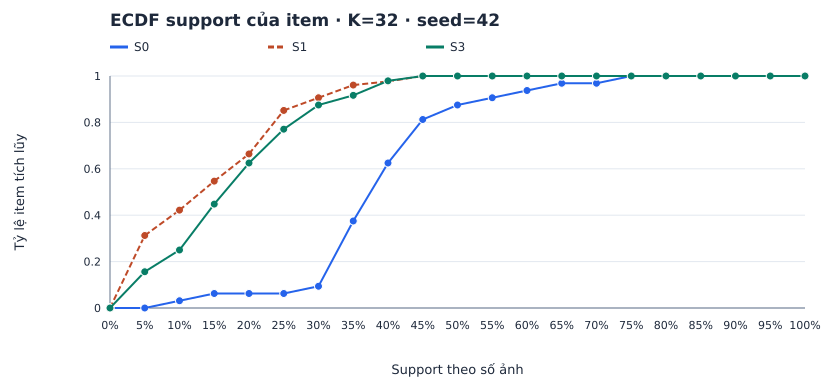

In [6]:
function phan_tich_support(ctx; k_minh_hoa)
    dong = doc_bang(ctx, "transactions", "item_support_summary_45.csv")
    nguong = ctx.config["pilot"]["minsup_fractions"]
    chuoi = [bien_the => [
        begin
            nhom = [r for r in dong if parse(Int, r["K"]) == k_minh_hoa &&
                r["variant"] == bien_the && parse(Float64, r["minsup_fraction"]) == muc]
            length(nhom) == length(EDA2.EXPECTED_SEEDS) ?
                mean(parse(Int, r["frequent_singletons"]) for r in nhom) : missing
        end for muc in nguong
    ] for bien_the in EDA2.VARIANTS]
    nhan = ["$(dinh_dang(100 * muc))%" for muc in nguong]
    bang = [(nhan[i], (last(day)[i] for day in chuoi)...) for i in eachindex(nguong)]
    hien_bang("Số item đơn phổ biến tại K=$k_minh_hoa", ["Support"; EDA2.VARIANTS], bang)
    hinh = ve_xu_huong(ctx, "b2_support", "Item đơn phổ biến theo ngưỡng tại K=$k_minh_hoa",
        nhan, chuoi; truc_x="Support tối thiểu", truc_y="Số item đơn")
    seed = SEED_MINH_HOA
    item_files = EDA2.output_path(ctx, "transactions", "item_support_by_database")
    thresholds_ecdf = collect(0.0:0.05:1.0)
    ecdf = [variant => begin
        file = joinpath(item_files, "B0_K$(k_minh_hoa)_seed$(seed)_$(variant).csv")
        _, items = EDA2._read_csv(file)
        supports = parse.(Float64, getindex.(items, "support_fraction"))
        [count(x -> x <= cut, supports) / length(supports) for cut in thresholds_ecdf]
    end for variant in EDA2.VARIANTS]
    hinh_ecdf = ve_xu_huong(ctx, "b2_support_ecdf", "ECDF support của item · K=$k_minh_hoa · seed=$seed",
        ["$(round(Int, x*100))%" for x in thresholds_ecdf], ecdf;
        truc_x="Support theo số ảnh", truc_y="Tỷ lệ item tích lũy", mien_y=(0,1))
    return (chi_tiet=dong, bang=bang, hinh=[hinh, hinh_ecdf],
        thu_muc_tung_item=EDA2.output_path(ctx, "transactions", "item_support_by_database"))
end

ket_qua_b2 = phan_tich_support(ctx; k_minh_hoa=K_MINH_HOA);


## B3. Độ đa dạng của giao dịch

Hai ảnh có cùng danh sách item được tính là hai TID có nội dung trùng. Tỷ lệ giao dịch phân biệt và Jaccard trả lời hai câu hỏi khác nhau: bao nhiêu nội dung khác nhau xuất hiện và mỗi cặp ảnh chia sẻ bao nhiêu item. Jaccard dùng chung một mẫu cặp TID cho mọi cấu hình.


### Tỷ lệ giao dịch phân biệt (%)

| K | S0 | S1 | S3 |
| --- | --- | --- | --- |
| 16 | 21.8638 | 95.7357 | 89.1229 |
| 32 | 92.3024 | 99.2395 | 99.2805 |
| 64 | 99.3171 | 99.9176 | 99.9071 |
| 128 | 99.9348 | 99.9776 | 99.9733 |
| 256 | 99.9795 | 99.9833 | 99.9814 |


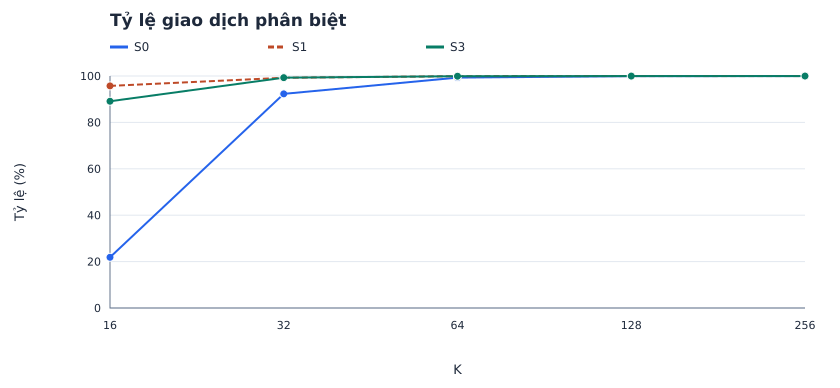

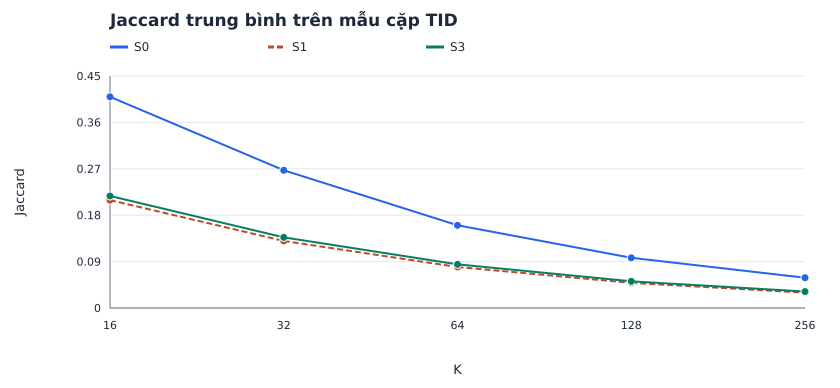

In [7]:
function phan_tich_da_dang(ctx)
    dong = doc_bang(ctx, "transactions", "transaction_diversity_45.csv")
    bang = hien_bang_theo_k("Tỷ lệ giao dịch phân biệt (%)", dong, "unique_ratio"; he_so=100)
    hinh_phan_biet = ve_theo_k(ctx, dong, "unique_ratio", "b3_phan_biet",
        "Tỷ lệ giao dịch phân biệt"; truc_y="Tỷ lệ (%)", he_so=100, mien_y=(0, 100))
    hinh_jaccard = ve_theo_k(ctx, dong, "jaccard_mean", "b3_jaccard",
        "Jaccard trung bình trên mẫu cặp TID"; truc_y="Jaccard")
    return (chi_tiet=dong, bang=bang, hinh=[hinh_phan_biet, hinh_jaccard])
end

ket_qua_b3 = phan_tich_da_dang(ctx);


## B4. Kiểm tra mã hóa vị trí

Khi bỏ mã vùng của S1 hoặc mã dải của S3, tập word phải khớp S0 trên từng TID. Bảng chi tiết còn cho biết tỷ lệ ảnh có ít nhất một item ở mỗi vùng hoặc dải của cấu hình minh họa. Một ảnh có thể được tính ở nhiều vùng.


### Kiểm tra word và trạng thái rỗng so với S0

| Biến thể | Số bộ khớp |
| --- | --- |
| S1 | 15 |
| S3 | 15 |


### Tỷ lệ ảnh theo vùng tại K=32, seed=42

| Biến thể | Vùng hoặc dải | Số ô patch | Số ảnh | Tỷ lệ (%) |
| --- | --- | --- | --- | --- |
| S1 | Trên trái | 9 | 57111 | 81.5871 |
| S1 | Trên phải | 12 | 69839 | 99.77 |
| S1 | Dưới trái | 12 | 69981 | 99.9729 |
| S1 | Dưới phải | 16 | 69992 | 99.9886 |
| S3 | Dải trên | 14 | 62457 | 89.2243 |
| S3 | Dải giữa | 21 | 69999 | 99.9986 |
| S3 | Dải dưới | 14 | 64616 | 92.3086 |


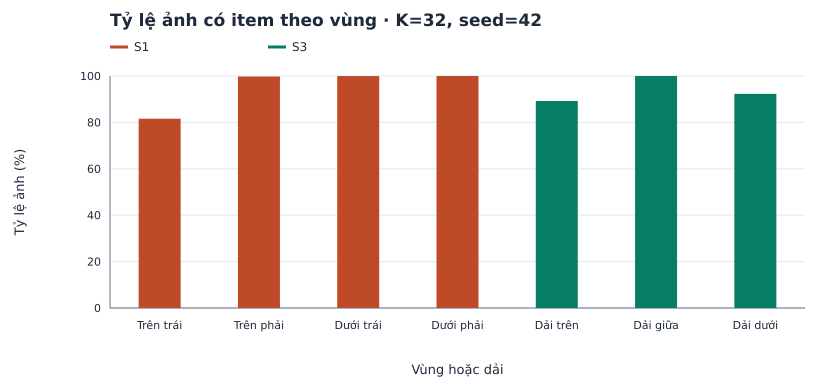

In [8]:
function kiem_tra_ma_hoa(ctx; k_minh_hoa, seed_minh_hoa)
    doi_chieu = doc_bang(ctx, "transactions", "spatial_invariants_45.csv")
    vung = doc_bang(ctx, "transactions", "region_support_summary.csv")
    hien_bang("Kiểm tra word và trạng thái rỗng so với S0",
        ["Biến thể", "Số bộ khớp"],
        [(bien_the, count(r -> r["variant"] == bien_the &&
            r["invariant_status"] == "PROJECTION_AND_EMPTY_STATUS_PASS", doi_chieu))
            for bien_the in ("S1", "S3")])
    mau = [r for r in vung if r["K"] == string(k_minh_hoa) && r["seed"] == string(seed_minh_hoa)]
    nhan_vung = Dict("top_left"=>"Trên trái", "top_right"=>"Trên phải", "bottom_left"=>"Dưới trái",
        "bottom_right"=>"Dưới phải", "top"=>"Dải trên", "middle"=>"Dải giữa", "bottom"=>"Dải dưới")
    ten_vung(r) = get(nhan_vung, lowercase(r["region_label"]), r["region_label"])
    hien_bang("Tỷ lệ ảnh theo vùng tại K=$k_minh_hoa, seed=$seed_minh_hoa",
        ["Biến thể", "Vùng hoặc dải", "Số ô patch", "Số ảnh", "Tỷ lệ (%)"],
        [(r["variant"], ten_vung(r), r["patch_slot_capacity"], r["image_support_count"],
            100 * parse(Float64, r["image_support_fraction"])) for r in mau])
    nhan = [ten_vung(r) for r in mau]
    chuoi = [bien_the => [r["variant"] == bien_the ? 100 * parse(Float64, r["image_support_fraction"]) :
        missing for r in mau] for bien_the in ("S1", "S3")]
    hinh = ve_xu_huong(ctx, "b4_vung", "Tỷ lệ ảnh có item theo vùng · K=$k_minh_hoa, seed=$seed_minh_hoa",
        nhan, chuoi; truc_x="Vùng hoặc dải", truc_y="Tỷ lệ ảnh (%)", mien_y=(0, 100), dang_cot=true)
    return (doi_chieu=doi_chieu, tat_ca_vung=vung, minh_hoa=mau, hinh=hinh)
end

ket_qua_b4 = kiem_tra_ma_hoa(ctx; k_minh_hoa=K_MINH_HOA, seed_minh_hoa=SEED_MINH_HOA);


## B5. Tương đồng của ảnh cùng lớp và khác lớp

B5 dùng cùng mẫu cặp ảnh cho toàn bộ cấu hình. **Chênh lệch Jaccard** là trung bình cùng lớp trừ trung bình khác lớp. **AUC** đo khả năng xếp cặp cùng lớp cao hơn cặp khác lớp theo Jaccard. Nhãn ảnh được dùng ở bước đánh giá hậu nghiệm.


### AUC trung bình qua ba seed

| K | S0 | S1 | S3 |
| --- | --- | --- | --- |
| 16 | 0.6238 | 0.6957 | 0.697 |
| 32 | 0.6371 | 0.6845 | 0.6955 |
| 64 | 0.6353 | 0.6677 | 0.6811 |
| 128 | 0.6314 | 0.6548 | 0.6647 |
| 256 | 0.624 | 0.6417 | 0.6471 |


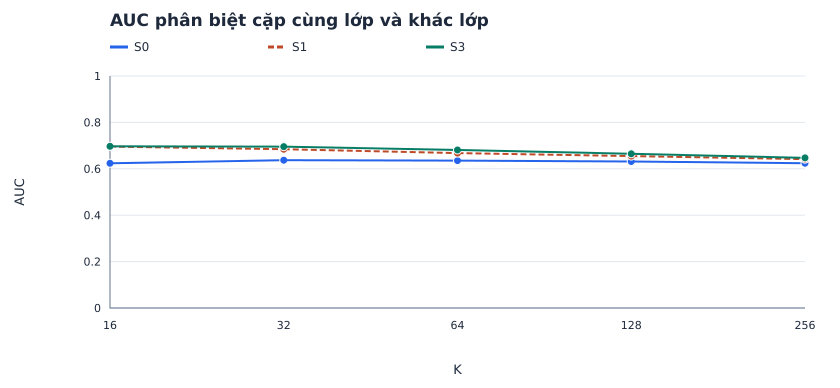

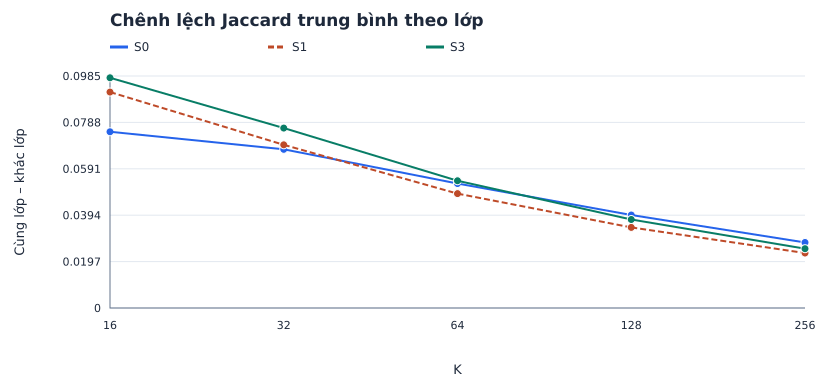

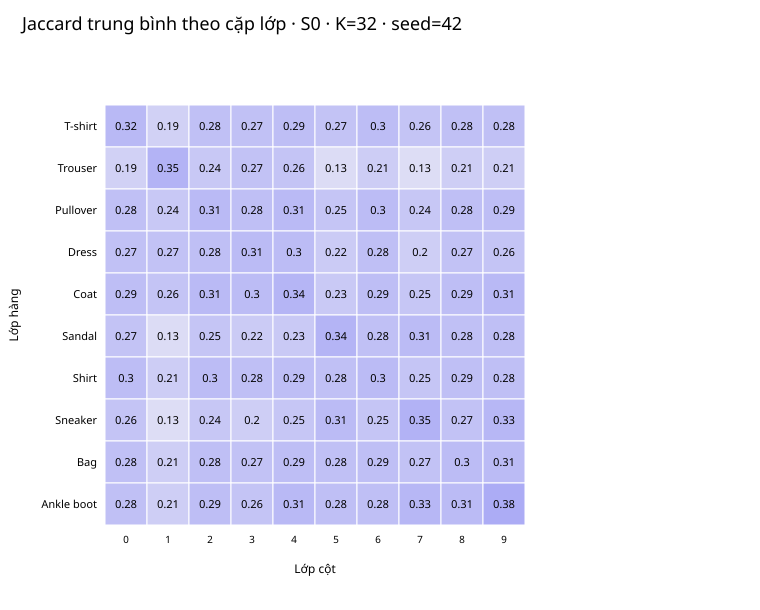

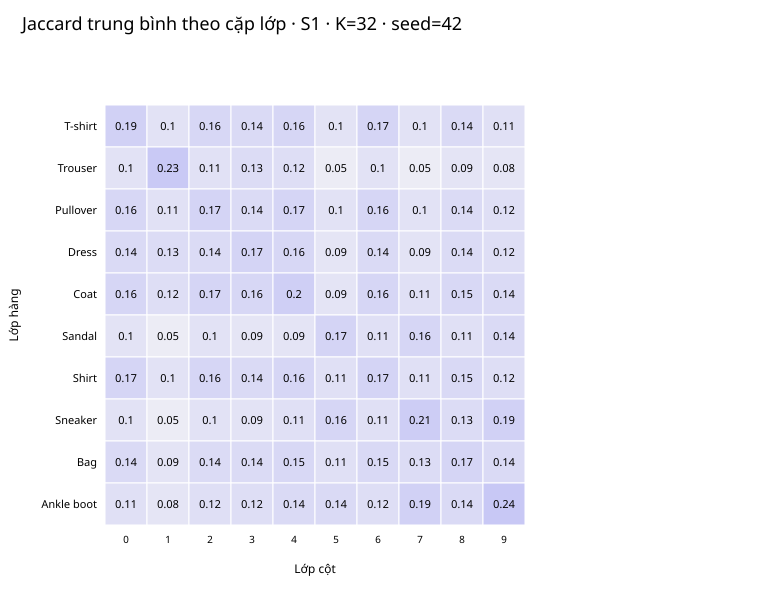

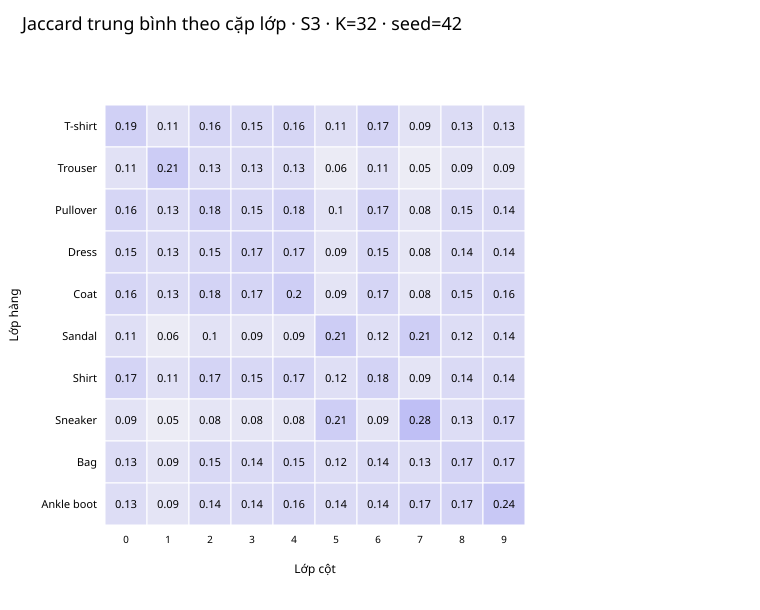

In [9]:
function phan_tich_tuong_dong_lop(ctx)
    dong = doc_bang(ctx, "transactions", "class_similarity_summary_45.csv")
    bang = hien_bang_theo_k("AUC trung bình qua ba seed", dong, "pair_discrimination_auc")
    hinh_auc = ve_theo_k(ctx, dong, "pair_discrimination_auc", "b5_auc",
        "AUC phân biệt cặp cùng lớp và khác lớp"; truc_y="AUC", mien_y=(0, 1))
    khoang_cach = [v for r in dong for v in [so_thuc(r["separation_gap"])] if !ismissing(v)]
    do_rong = max(0.02, isempty(khoang_cach) ? 0.0 : maximum(abs, khoang_cach))
    duoi = any(<(0), khoang_cach) ? -do_rong : 0.0
    hinh_gap = ve_theo_k(ctx, dong, "separation_gap", "b5_chenh_lech",
        "Chênh lệch Jaccard trung bình theo lớp"; truc_y="Cùng lớp – khác lớp", mien_y=(duoi, do_rong))
    theo_lop = doc_bang(ctx, "transactions", "classwise_similarity.csv")
    theo_cap = doc_bang(ctx, "transactions", "class_pair_similarity.csv")
    heatmaps = [ve_heatmap_lop(ctx, theo_lop, theo_cap, K_MINH_HOA, SEED_MINH_HOA, variant)
        for variant in EDA2.VARIANTS]
    return (chi_tiet=dong, bang=bang, hinh=[hinh_auc, hinh_gap, heatmaps...],
        theo_lop=EDA2.output_path(ctx, "transactions", "classwise_similarity.csv"),
        theo_cap_lop=EDA2.output_path(ctx, "transactions", "class_pair_similarity.csv"))
end

ket_qua_b5 = phan_tich_tuong_dong_lop(ctx);


## C1. Chạy Eclat khảo sát trên 45 bộ

C1 dùng chung support **3%** (ít nhất 2.100 ảnh) và giới hạn itemset dài **2 item**. Biểu đồ chỉ dùng lượt hoàn thành. Thời gian là số đo của lượt khảo sát, gồm cả bước đọc dữ liệu. Nếu bật chạy lại, bộ máy Eclat vẫn có thể dùng checkpoint khớp dữ liệu và cấu hình.


### Trạng thái C1

| Trạng thái | Số bộ |
| --- | --- |
| `COMPLETED_LENGTH_CAPPED` | 45 |


### Số cặp item phổ biến ở ngưỡng 3%

| K | S0 | S1 | S3 |
| --- | --- | --- | --- |
| 16 | 120 | 1041.3333 | 764.6667 |
| 32 | 479 | 1921.3333 | 1688.6667 |
| 64 | 1471.3333 | 1616.6667 | 1535 |
| 128 | 1545 | 577.3333 | 561 |
| 256 | 661 | 155 | 164 |


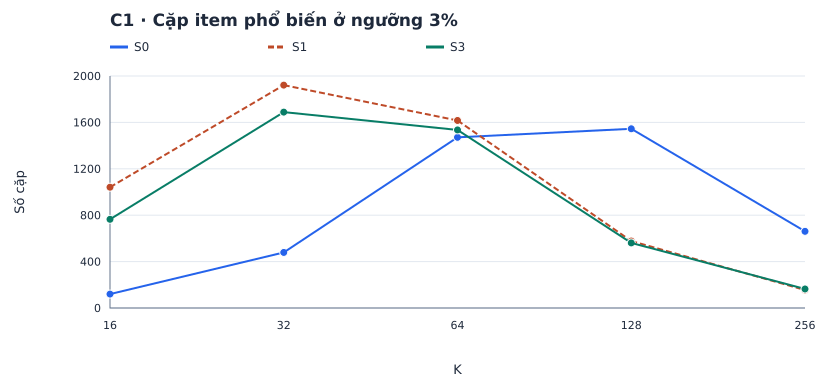

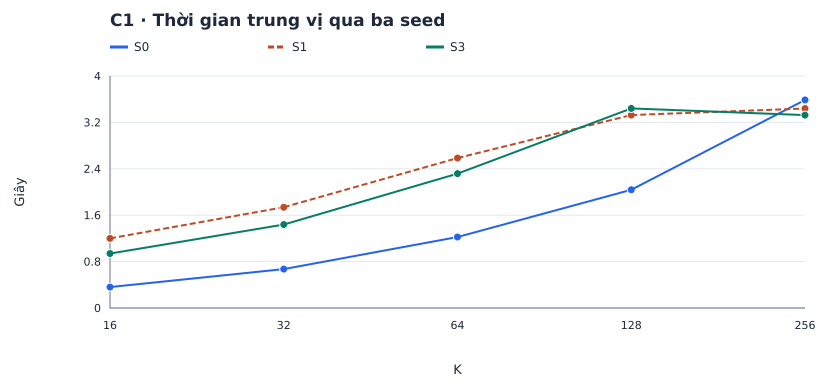

In [10]:
function chay_c1(ctx; tinh_lai=false)
    tep = ("pilot_eclat", "pilot_common_45.csv")
    dong = co_bang(ctx, tep...) ? doc_bang(ctx, tep...) : []
    ids = Set(s.database_id for s in ctx.specs)
    danh_muc = Dict(r["database_id"] => r for r in doc_bang(ctx, "input_manifest.csv"))
    ma_cau_hinh = bytes2hex(open(sha256, ctx.config_path))
    ma_engine = bytes2hex(open(sha256, joinpath(thu_muc_du_an, "src", "algorithm", "EclatBaseline.jl")))
    ma_adapter = bytes2hex(open(sha256, joinpath(thu_muc_du_an, "src", "eda2", "FashionMNISTEDA2.jl")))
    cung_nguon = length(dong) == length(ids) && Set(r["database_id"] for r in dong) == ids &&
        all(r -> r["source_sha256"] == danh_muc[r["database_id"]]["source_sha256"] &&
                 r["config_sha256"] == ma_cau_hinh && r["engine_source_sha256"] == ma_engine &&
                 r["adapter_source_sha256"] == ma_adapter, dong)
    if tinh_lai || !cung_nguon
        EDA2.run_common_pilot!(ctx)
        dong = doc_bang(ctx, tep...)
    end
    hoan_tat = [r for r in dong if r["status"] == "COMPLETED_LENGTH_CAPPED"]
    trang_thai = sort!(unique([r["status"] for r in dong]))
    hien_bang("Trạng thái C1", ["Trạng thái", "Số bộ"],
        [(ten, count(r -> r["status"] == ten, dong)) for ten in trang_thai])
    bang = hien_bang_theo_k("Số cặp item phổ biến ở ngưỡng 3%", hoan_tat, "frequent_2_count")
    hinh_cap = ve_theo_k(ctx, hoan_tat, "frequent_2_count", "c1_cap_item",
        "C1 · Cặp item phổ biến ở ngưỡng 3%"; truc_y="Số cặp")
    hinh_thoi_gian = ve_theo_k(ctx, hoan_tat, "runtime_s", "c1_thoi_gian",
        "C1 · Thời gian trung vị qua ba seed"; truc_y="Giây", thong_ke=median)
    return (chi_tiet=dong, hoan_tat=hoan_tat, bang=bang, hinh=[hinh_cap, hinh_thoi_gian])
end

ket_qua_c1 = chay_c1(ctx; tinh_lai=TAO_LAI_C1);


## C2. Duyệt danh sách cấu hình đi tiếp

Chọn theo cặp **(K, seed)**. Mỗi cặp đi tiếp với đủ S0, S1 và S3. Tệp **pilot_eclat/shortlist_decision.csv** được tạo nếu còn thiếu. Khi đã có tệp, cell chỉ đọc quyết định.

Điền **selected=true**, **decision_reason** và **metrics_used** cho các cấu hình được chọn. Ưu tiên độ phủ K, độ ổn định theo seed, chi phí và kết quả khảo sát. Nếu dùng kết quả B5 để chọn, ghi **label_informed_selection=true**. Chạy lại cell C2 sau khi chỉnh tệp để xem bảng cập nhật.


In [11]:
function doc_shortlist(ctx)
    tep = EDA2.output_path(ctx, "pilot_eclat", "shortlist_decision.csv")
    (!isfile(tep) || any(isempty(strip(r["metrics_used"])) for r in doc_bang(ctx, "pilot_eclat", "shortlist_decision.csv"))) && EDA2.prepare_shortlist!(ctx)
    dong = doc_bang(ctx, "pilot_eclat", "shortlist_decision.csv")
    duoc_chon(r) = lowercase(strip(r["selected"])) == "true"
    du_dieu_kien(r) = lowercase(strip(r["rejected_for_invalidity"])) == "false"
    bang = [(r["K"], r["seed"], du_dieu_kien(r) ? "Có" : "Không", duoc_chon(r) ? "Có" : "Không",
        r["decision_reason"]) for r in dong]
    hien_bang("Quyết định theo codebook", ["K", "Seed", "Đủ điều kiện", "Đã chọn", "Lý do"], bang)
    da_chon = [(parse(Int, r["K"]), parse(Int, r["seed"])) for r in dong if duoc_chon(r)]
    println("Đã chọn $(length(da_chon))/$(length(dong)) codebook.")
    codebooks = doc_bang(ctx, "codebook", "codebook_metrics_15.csv")
    transactions = doc_bang(ctx, "transactions", "transaction_metrics_45.csv")
    diversities = doc_bang(ctx, "transactions", "transaction_diversity_45.csv")
    c1 = doc_bang(ctx, "pilot_eclat", "pilot_common_45.csv")
    bang_bang_chung = []
    for r in dong, variant in EDA2.VARIANTS
        k, seed = r["K"], r["seed"]
        dbid = "B0_K$(k)_seed$(seed)_$(variant)"
        a = only(filter(x -> x["K"] == k && x["seed"] == seed, codebooks))
        t = only(filter(x -> x["database_id"] == dbid, transactions))
        d = only(filter(x -> x["database_id"] == dbid, diversities))
        m = only(filter(x -> x["database_id"] == dbid, c1))
        push!(bang_bang_chung, (k, seed, variant, a["convergence_status"],
            m["status"], m["frequent_1_count"], m["frequent_2_count"],
            so_thuc(t["mean_length"]), 100 * so_thuc(d["unique_ratio"]), so_thuc(m["runtime_s"])))
    end
    hien_bang("Bằng chứng dùng để duyệt C2 · đủ 45 bộ",
        ["K", "Seed", "Biến thể", "Hội tụ", "Trạng thái C1", "Item đơn", "Cặp", "Độ dài TB", "Giao dịch phân biệt (%)", "C1 (giây)"],
        bang_bang_chung)
    return (duong_dan=tep, chi_tiet=dong, da_chon=da_chon)
end

ket_qua_c2 = doc_shortlist(ctx);


### Quyết định theo codebook

| K | Seed | Đủ điều kiện | Đã chọn | Lý do |
| --- | --- | --- | --- | --- |
| 16 | 42 | Có | Không | `NOT_IN_APPROVED_C2_SHORTLIST` |
| 16 | 123 | Có | Có | C2 approved: preserve all-K coverage, retain three seeds at K=32 and K=64, and keep paired S0/S1/S3 comparisons. Selection uses A/B/C1 evidence only, not B5 class-label similarity. |
| 16 | 2026 | Có | Không | `NOT_IN_APPROVED_C2_SHORTLIST` |
| 32 | 42 | Có | Có | C2 approved: preserve all-K coverage, retain three seeds at K=32 and K=64, and keep paired S0/S1/S3 comparisons. Selection uses A/B/C1 evidence only, not B5 class-label similarity. |
| 32 | 123 | Có | Có | C2 approved: preserve all-K coverage, retain three seeds at K=32 and K=64, and keep paired S0/S1/S3 comparisons. Selection uses A/B/C1 evidence only, not B5 class-label similarity. |
| 32 | 2026 | Có | Có | C2 approved: preserve all-K coverage, retain three seeds at K=32 and K=64, and keep paired S0/S1/S3 comparisons. Selection uses A/B/C1 evidence only, not B5 class-label similarity. |
| 64 | 42 | Có | Có | C2 approved: preserve all-K coverage, retain three seeds at K=32 and K=64, and keep paired S0/S1/S3 comparisons. Selection uses A/B/C1 evidence only, not B5 class-label similarity. |
| 64 | 123 | Có | Có | C2 approved: preserve all-K coverage, retain three seeds at K=32 and K=64, and keep paired S0/S1/S3 comparisons. Selection uses A/B/C1 evidence only, not B5 class-label similarity. |
| 64 | 2026 | Có | Có | C2 approved: preserve all-K coverage, retain three seeds at K=32 and K=64, and keep paired S0/S1/S3 comparisons. Selection uses A/B/C1 evidence only, not B5 class-label similarity. |
| 128 | 42 | Có | Không | `NOT_IN_APPROVED_C2_SHORTLIST` |
| 128 | 123 | Có | Có | C2 approved: preserve all-K coverage, retain three seeds at K=32 and K=64, and keep paired S0/S1/S3 comparisons. Selection uses A/B/C1 evidence only, not B5 class-label similarity. |
| 128 | 2026 | Có | Không | `NOT_IN_APPROVED_C2_SHORTLIST` |
| 256 | 42 | Có | Có | C2 approved: preserve all-K coverage, retain three seeds at K=32 and K=64, and keep paired S0/S1/S3 comparisons. Selection uses A/B/C1 evidence only, not B5 class-label similarity. |
| 256 | 123 | Có | Không | `NOT_IN_APPROVED_C2_SHORTLIST` |
| 256 | 2026 | Có | Không | `NOT_IN_APPROVED_C2_SHORTLIST` |


Đã chọn 9/15 codebook.


### Bằng chứng dùng để duyệt C2 · đủ 45 bộ

| K | Seed | Biến thể | Hội tụ | Trạng thái C1 | Item đơn | Cặp | Độ dài TB | Giao dịch phân biệt (%) | C1 (giây) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 16 | 42 | S0 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 16 | 120 | 8.5676 | 18.2229 | 0.6175 |
| 16 | 42 | S1 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 58 | 996 | 15.2529 | 95.1714 | 1.2135 |
| 16 | 42 | S3 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 45 | 727 | 13.1997 | 87.6157 | 0.9436 |
| 16 | 123 | S0 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 16 | 120 | 9.0047 | 23.6857 | 0.3335 |
| 16 | 123 | S1 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 59 | 1065 | 15.5565 | 96.0257 | 1.1566 |
| 16 | 123 | S3 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 44 | 783 | 13.5377 | 89.8829 | 0.9118 |
| 16 | 2026 | S0 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 16 | 120 | 9.0052 | 23.6829 | 0.3613 |
| 16 | 2026 | S1 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 59 | 1063 | 15.5555 | 96.01 | 1.2004 |
| 16 | 2026 | S3 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 44 | 784 | 13.5381 | 89.87 | 0.939 |
| 32 | 42 | S0 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 32 | 471 | 12.2827 | 92.01 | 0.6734 |
| 32 | 42 | S1 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 102 | 1933 | 18.2272 | 99.2571 | 1.7373 |
| 32 | 42 | S3 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 84 | 1696 | 16.544 | 99.2257 | 1.4628 |
| 32 | 123 | S0 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 32 | 482 | 12.2729 | 92.3743 | 0.6697 |
| 32 | 123 | S1 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 102 | 1905 | 18.2045 | 99.1329 | 1.7213 |
| 32 | 123 | S3 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 84 | 1658 | 16.4809 | 99.3757 | 1.4389 |
| 32 | 2026 | S0 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 32 | 484 | 12.278 | 92.5229 | 0.671 |
| 32 | 2026 | S1 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 108 | 1926 | 18.2348 | 99.3286 | 1.7468 |
| 32 | 2026 | S3 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 85 | 1712 | 16.5245 | 99.24 | 1.4378 |
| 64 | 42 | S0 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 64 | 1463 | 15.1304 | 99.3 | 1.261 |
| 64 | 42 | S1 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 169 | 1640 | 20.3691 | 99.9014 | 2.581 |
| 64 | 42 | S3 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 153 | 1551 | 18.8435 | 99.9186 | 2.2963 |
| 64 | 123 | S0 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 64 | 1472 | 15.1055 | 99.2514 | 1.2064 |
| 64 | 123 | S1 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 166 | 1591 | 20.2681 | 99.9143 | 2.5851 |
| 64 | 123 | S3 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 157 | 1514 | 18.7535 | 99.8929 | 2.3169 |
| 64 | 2026 | S0 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 64 | 1479 | 15.1534 | 99.4 | 1.2239 |
| 64 | 2026 | S1 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 171 | 1619 | 20.3072 | 99.9371 | 2.6081 |
| 64 | 2026 | S3 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 153 | 1540 | 18.778 | 99.91 | 2.4985 |
| 128 | 42 | S0 | `NON_CONVERGED` | `COMPLETED_LENGTH_CAPPED` | 128 | 1559 | 17.9858 | 99.9429 | 2.1046 |
| 128 | 42 | S1 | `NON_CONVERGED` | `COMPLETED_LENGTH_CAPPED` | 239 | 559 | 22.3123 | 99.98 | 3.3342 |
| 128 | 42 | S3 | `NON_CONVERGED` | `COMPLETED_LENGTH_CAPPED` | 246 | 538 | 21.041 | 99.9743 | 3.3983 |
| 128 | 123 | S0 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 128 | 1576 | 17.9909 | 99.9371 | 1.9898 |
| 128 | 123 | S1 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 233 | 590 | 22.3992 | 99.9757 | 3.308 |
| 128 | 123 | S3 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 249 | 579 | 21.0996 | 99.9671 | 3.4408 |
| 128 | 2026 | S0 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 128 | 1500 | 17.9165 | 99.9243 | 2.0384 |
| 128 | 2026 | S1 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 238 | 583 | 22.3644 | 99.9771 | 3.3267 |
| 128 | 2026 | S3 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 250 | 566 | 21.0674 | 99.9786 | 3.5529 |
| 256 | 42 | S0 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 240 | 690 | 20.5108 | 99.98 | 3.5872 |
| 256 | 42 | S1 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 284 | 165 | 24.1562 | 99.9857 | 3.4394 |
| 256 | 42 | S3 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 281 | 165 | 23.1084 | 99.9814 | 3.3274 |
| 256 | 123 | S0 | `NON_CONVERGED` | `COMPLETED_LENGTH_CAPPED` | 240 | 651 | 20.2911 | 99.9771 | 3.6173 |
| 256 | 123 | S1 | `NON_CONVERGED` | `COMPLETED_LENGTH_CAPPED` | 283 | 157 | 24.0043 | 99.9814 | 3.3509 |
| 256 | 123 | S3 | `NON_CONVERGED` | `COMPLETED_LENGTH_CAPPED` | 282 | 171 | 22.9213 | 99.98 | 3.3062 |
| 256 | 2026 | S0 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 236 | 642 | 20.3137 | 99.9814 | 3.5016 |
| 256 | 2026 | S1 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 292 | 143 | 23.9707 | 99.9829 | 3.5365 |
| 256 | 2026 | S3 | CONVERGED | `COMPLETED_LENGTH_CAPPED` | 283 | 156 | 22.879 | 99.9829 | 3.3255 |


## C3. Chạy sâu và kiểm tra độ nhạy

C3 dùng các ngưỡng **1%, 3%, 5%, 10%** và giới hạn độ dài **4 item**. Mỗi cấu hình được khởi động một lần rồi đo ba lượt theo cấu hình mặc định. Bảng dưới báo trạng thái. Nếu có kết quả hoàn chỉnh, biểu đồ minh họa tổng số itemset và thời gian trung vị theo ngưỡng cho một cặp K, seed trong shortlist.

Đặt **CHAY_C3 = true** sau khi duyệt C2 để chạy mới. Khi cờ tắt, cell đọc kết quả C3 đã lưu nếu kết quả thuộc shortlist hiện tại.


### Trạng thái C3 trong shortlist hiện tại

| Trạng thái | Số lượt |
| --- | --- |
| `COMPLETED_LENGTH_CAPPED` | 108 |


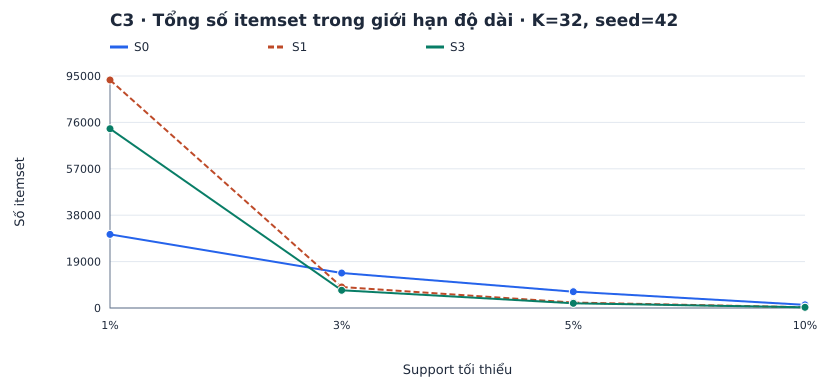

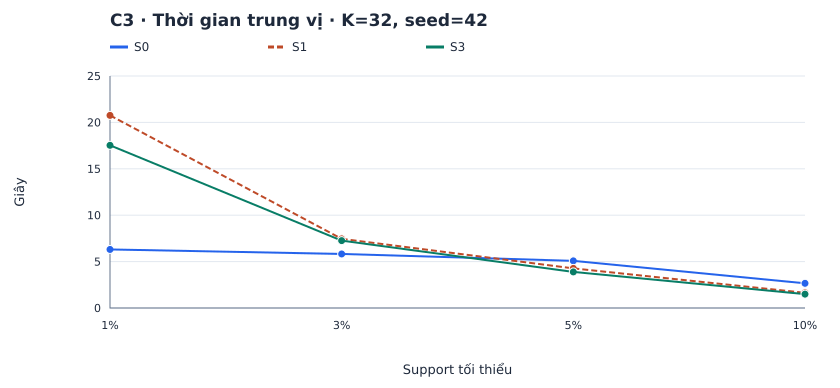

In [12]:
function phan_tich_chay_sau(ctx, shortlist; chay_moi=false, k_minh_hoa, seed_minh_hoa)
    tep = ("pilot_eclat", "pilot_deep_runs.csv")
    if isempty(shortlist.da_chon)
        println("C3 đang chờ chọn ít nhất một codebook ở C2.")
        return (trang_thai=:cho_shortlist, chi_tiet=[], hinh=[])
    end
    chay_moi && EDA2.run_deep_pilot!(ctx)
    if !co_bang(ctx, tep...)
        println("Chưa có kết quả C3. Bật CHAY_C3 để chạy các cấu hình đã chọn.")
        return (trang_thai=:chua_chay, chi_tiet=[], hinh=[])
    end
    thuoc_shortlist(r) = (parse(Int, r["K"]), parse(Int, r["seed"])) in shortlist.da_chon
    dong = filter(thuoc_shortlist, doc_bang(ctx, tep...))
    trang_thai = sort!(unique([r["completion_status"] for r in dong]))
    hien_bang("Trạng thái C3 trong shortlist hiện tại", ["Trạng thái", "Số lượt"],
        [(ten, count(r -> r["completion_status"] == ten, dong)) for ten in trang_thai])
    hoan_tat = [r for r in dong if r["completion_status"] == "COMPLETED_LENGTH_CAPPED" && !isempty(r["output_ref"])]
    isempty(hoan_tat) && return (trang_thai=:chua_co_luot_hoan_tat, chi_tiet=dong, hinh=[])
    cap_co_du_lieu = sort!(unique([(parse(Int, r["K"]), parse(Int, r["seed"])) for r in hoan_tat]))
    cap_minh_hoa = (k_minh_hoa, seed_minh_hoa)
    k, seed = cap_minh_hoa in cap_co_du_lieu ? cap_minh_hoa : first(cap_co_du_lieu)
    nguong = ctx.config["pilot"]["minsup_fractions"]
    nhan = ["$(dinh_dang(100 * muc))%" for muc in nguong]
    dem = co_bang(ctx, "pilot_eclat", "pilot_itemset_counts.csv") ?
        doc_bang(ctx, "pilot_eclat", "pilot_itemset_counts.csv") : []
    loc(r, bien_the, muc) = r["K"] == string(k) && r["seed"] == string(seed) &&
        r["variant"] == bien_the && parse(Float64, r["minsup_fraction"]) == muc
    function so_mau(bien_the, muc)
        luot = findfirst(r -> loc(r, bien_the, muc), hoan_tat)
        isnothing(luot) && return missing
        dem_mau = [parse(Int, r["itemset_count"]) for r in dem if loc(r, bien_the, muc)]
        return length(dem_mau) == parse(Int, hoan_tat[luot]["max_length"]) ? sum(dem_mau) : missing
    end
    function thoi_gian(bien_the, muc)
        luot = findfirst(r -> loc(r, bien_the, muc), hoan_tat)
        return isnothing(luot) ? missing : so_thuc(hoan_tat[luot]["runtime_median_s"])
    end
    ve(ten, tieu_de, don_vi, doc_gia_tri) = ve_xu_huong(ctx, ten,
        "$tieu_de · K=$k, seed=$seed", nhan,
        [v => [doc_gia_tri(v, muc) for muc in nguong] for v in EDA2.VARIANTS];
        truc_x="Support tối thiểu", truc_y=don_vi)
    hinh_mau = ve("c3_so_mau", "C3 · Tổng số itemset trong giới hạn độ dài", "Số itemset", so_mau)
    hinh_thoi_gian = ve("c3_thoi_gian", "C3 · Thời gian trung vị", "Giây", thoi_gian)
    return (trang_thai=:co_ket_qua, chi_tiet=dong, minh_hoa=(k, seed), hinh=[hinh_mau, hinh_thoi_gian])
end

ket_qua_c3 = phan_tich_chay_sau(ctx, ket_qua_c2; chay_moi=CHAY_C3,
    k_minh_hoa=K_MINH_HOA, seed_minh_hoa=SEED_MINH_HOA);


## D. Diễn giải mẫu đại diện

Sau C3, nhóm mẫu ở support 3% theo độ dài rồi lấy đại diện quanh các phân vị support 25%, 50% và 75%. Bảng minh họa hiển thị cách giải mã item, số ảnh chứa mẫu và TID ví dụ. Đặt **TAO_MAU_DIEN_GIAI = true** để tạo bảng lần đầu. Ghi nhận xét về mẫu trong tệp kết quả sau khi xem ảnh.


### Mẫu đại diện (tối đa 12 dòng)

| Bộ dữ liệu | Item đã giải mã | Số ảnh | TID ví dụ |
| --- | --- | --- | --- |
| `B0_K16_seed123_S0` | `word_4` | 35444 | 1,2,3,4,5 |
| `B0_K16_seed123_S0` | `word_3` | 38863 | 1,2,5,7,8 |
| `B0_K16_seed123_S0` | `word_16` | 40757 | 1,2,4,6,7 |
| `B0_K16_seed123_S0` | word_2;word_16 | 18508 | 1,6,8,9,10 |
| `B0_K16_seed123_S0` | word_1;word_11 | 21911 | 2,5,6,7,8 |
| `B0_K16_seed123_S0` | word_7;word_10 | 26327 | 8,9,10,11,12 |
| `B0_K16_seed123_S0` | word_3;word_5;word_15 | 9575 | 2,17,19,22,23 |
| `B0_K16_seed123_S0` | word_4;word_7;word_12 | 12805 | 5,8,12,16,21 |
| `B0_K16_seed123_S0` | word_2;word_6;word_8 | 16098 | 6,8,10,11,12 |
| `B0_K16_seed123_S0` | word_9;word_12;word_15;word_16 | 5046 | 13,41,46,61,92 |
| `B0_K16_seed123_S0` | word_4;word_6;word_11;word_15 | 7287 | 2,5,19,27,29 |
| `B0_K16_seed123_S0` | word_3;word_4;word_12;word_14 | 9684 | 1,12,16,23,28 |


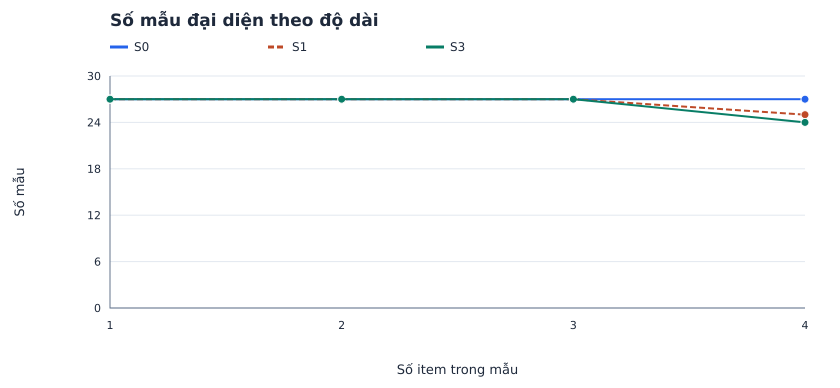

In [13]:
function xem_mau_dai_dien(ctx, shortlist, c3; tao_moi=false)
    tep = ("interpretability", "pattern_interpretability.csv")
    if c3.trang_thai != :co_ket_qua
        println("Cần kết quả C3 trước khi chọn mẫu đại diện.")
        return (trang_thai=:cho_c3, mau=[])
    end
    if tao_moi && !co_bang(ctx, tep...)
        du_luot_3_phan_tram = Set((parse(Int, r["K"]), parse(Int, r["seed"]), r["variant"])
            for r in c3.chi_tiet if parse(Float64, r["minsup_fraction"]) == 0.03)
        if !all((k, seed, v) in du_luot_3_phan_tram for (k, seed) in shortlist.da_chon for v in EDA2.VARIANTS)
            println("Hãy chạy C3 ở ngưỡng 3% cho đủ ba biến thể của mỗi cấu hình đã chọn.")
            return (trang_thai=:cho_c3, mau=[])
        end
        EDA2.prepare_pattern_review!(ctx)
    end
    if !co_bang(ctx, tep...)
        println("Chưa có bảng mẫu. Bật TAO_MAU_DIEN_GIAI để tạo.")
        return (trang_thai=:chua_co_mau, mau=[])
    end
    mau = [r for r in doc_bang(ctx, tep...) if (parse(Int, r["K"]), parse(Int, r["seed"])) in shortlist.da_chon]
    hien_bang("Mẫu đại diện (tối đa 12 dòng)", ["Bộ dữ liệu", "Item đã giải mã", "Số ảnh", "TID ví dụ"],
        [(r["database_id"], r["decoded_items"], r["support_count"], replace(r["example_tids"], ';' => ',')) for r in first(mau, min(12, length(mau)))])
    do_dai = 1:ctx.config["pilot"]["deep_max_itemset_length"]
    chuoi = [bien_the => [count(r -> r["variant"] == bien_the && length(split(r["itemset"])) == n, mau)
        for n in do_dai] for bien_the in EDA2.VARIANTS]
    hinh = isempty(mau) ? nothing : ve_xu_huong(ctx, "d_do_dai_mau", "Số mẫu đại diện theo độ dài",
        string.(do_dai), chuoi; truc_x="Số item trong mẫu", truc_y="Số mẫu")
    return (trang_thai=isempty(mau) ? :chua_co_mau : :co_mau, mau=mau,
        hinh=hinh, duong_dan=EDA2.output_path(ctx, tep...))
end

ket_qua_d = xem_mau_dai_dien(ctx, ket_qua_c2, ket_qua_c3; tao_moi=TAO_MAU_DIEN_GIAI);


## E. Tổng hợp bằng chứng

Dùng bảng C1 để đối chiếu số cặp phổ biến giữa các biến thể. Đọc B5 như chỉ số hậu nghiệm và kiểm tra mẫu đại diện ở D trước khi chốt cấu hình. Cell tổng hợp báo số lượt đã xong và số lựa chọn C2, sau đó dẫn tới báo cáo trên đĩa. Bật **GHI_LAI_BAO_CAO** khi muốn tạo lại báo cáo tự động ở trạng thái **INCONCLUSIVE**.


In [14]:
function tong_ket_eda2(ctx, ab, c1, c2, c3, d; ghi_lai=false)
    bao_cao = EDA2.output_path(ctx, "final", "final_selection.md")
    if ghi_lai || !isfile(bao_cao)
        EDA2.write_inconclusive_report!(ctx)
    end
    hang = [
        ("A", ab.bao_cao["validated_codebooks"], "Codebook đã kiểm định"),
        ("B", ab.bao_cao["validated_databases"], "Bộ giao dịch đã kiểm định"),
        ("C1", length(c1.hoan_tat), "Bộ giao dịch hoàn thành trong giới hạn"),
        ("C2", length(c2.da_chon), "Codebook được chọn"),
        ("C3", count(r -> r["completion_status"] == "COMPLETED_LENGTH_CAPPED" &&
                      !isempty(r["output_ref"]), c3.chi_tiet), "Lượt có kết quả"),
        ("D", length(d.mau), "Mẫu có trong bảng diễn giải"),
    ]
    hien_bang("Tiến độ và bằng chứng hiện có", ["Phần", "Số lượng", "Đơn vị"], hang)
    return (bang=hang, bao_cao=bao_cao,
        so_sanh=EDA2.output_path(ctx, "final", "comparative_summary.csv"),
        thu_muc_hinh=EDA2.output_path(ctx, "figures", "notebook"))
end

ket_qua_e = tong_ket_eda2(ctx, ket_qua_00, ket_qua_c1, ket_qua_c2, ket_qua_c3, ket_qua_d;
    ghi_lai=GHI_LAI_BAO_CAO)


### Tiến độ và bằng chứng hiện có

| Phần | Số lượng | Đơn vị |
| --- | --- | --- |
| A | 15 | Codebook đã kiểm định |
| B | 45 | Bộ giao dịch đã kiểm định |
| C1 | 45 | Bộ giao dịch hoàn thành trong giới hạn |
| C2 | 9 | Codebook được chọn |
| C3 | 108 | Lượt có kết quả |
| D | 319 | Mẫu có trong bảng diễn giải |


(bang = [("A", 15, "Codebook đã kiểm định"), ("B", 45, "Bộ giao dịch đã kiểm định"), ("C1", 45, "Bộ giao dịch hoàn thành trong giới hạn"), ("C2", 9, "Codebook được chọn"), ("C3", 108, "Lượt có kết quả"), ("D", 319, "Mẫu có trong bảng diễn giải")], bao_cao = "/run/media/fernir/Data/Documents/HCMUS/SEMESTER7/DataMining/TeamProject-FrequentItemsetMining/results/fashion/eda2/v2/final/final_selection.md", so_sanh = "/run/media/fernir/Data/Documents/HCMUS/SEMESTER7/DataMining/TeamProject-FrequentItemsetMining/results/fashion/eda2/v2/final/comparative_summary.csv", thu_muc_hinh = "/run/media/fernir/Data/Documents/HCMUS/SEMESTER7/DataMining/TeamProject-FrequentItemsetMining/results/fashion/eda2/v2/figures/notebook")